# Evaluación Parcial 2 - Spotify Tracks
## Inteligencia musical y predicción de popularidad de canciones

**Asignatura:** Machine Learning (MLY1101)  
**Caso:** C - Spotify Tracks  
**Integrantes:** Moira Bittner, Lucas Fernandez y Julian Martinez  
**Continuación de:** EP1 de Spotify (comprensión del negocio, EDA y limpieza).

Partimos de la preparación de la EP1 y comparamos **Ridge, Random Forest y Gradient Boosting** para estimar popularidad. Como aprendizaje no supervisado utilizamos **K-Means** para agrupar perfiles de sonido, **PCA** para identificar las dimensiones del sonido y un **agrupamiento jerárquico (Ward)** para validar los perfiles.

**Ejecución en Colab:** subir `Spotify_Tracks_Dataset.csv` cuando lo solicite la primera celda de carga y ejecutar las celdas en orden. También funciona dentro de la estructura `data/raw/`, `notebooks/`, `images/`, `models/`. Los procesos de validación cruzada y Random Forest pueden tardar bastante según el equipo.

**Control de evaluación:** las decisiones de selección se toman con entrenamiento/validación; el conjunto de prueba final se conserva para comparar modelos y describir sus errores, sin reajustarlos.

**Reproducibilidad:** todas las operaciones aleatorias usan la semilla 42. Las cifras comentadas en el texto corresponden a las salidas de esta ejecución (las versiones de las librerías se imprimen en la primera celda). `HistGradientBoostingRegressor` puede variar en centésimas entre equipos o versiones de scikit-learn; esas diferencias no cambian el orden de los modelos ni las conclusiones.

# 0. Metodología CRISP-DM

| Fase | Sección | Estado |
|---|---|---|
| 1. Comprensión del negocio | 1 | Retomada de EP1 |
| 2. Comprensión de los datos | 2 y 3 | Retomada de EP1 (resumen) |
| 3. Preparación de los datos | 2 y 4 | Retomada de EP1 y ajustada por modelo |
| 4. Modelado | 5, 6, 7 y 9 | **Desarrollada en EP2** |
| 5. Evaluación | 6, 8 y 10 | **Desarrollada en EP2** |
| 6. Despliegue (prototipo) | 10 | Exportación del modelo e instrucciones de uso; **no está desplegado en producción** |

# 1. Comprensión del negocio

Un sello discográfico debe decidir qué canciones revisar para sus campañas. Queremos estimar la **popularidad** (`popularity`, entre 0 y 100) mediante características musicales y género. Aunque es una variable discreta, se modela como **regresión**, porque interesa predecir su valor numérico.

K-Means responde una pregunta complementaria: **¿qué perfiles de sonido hay en el catálogo?** Sus grupos no representan categorías de éxito.

## 1.1 Criterios para evaluar la utilidad

La comparación principal es contra una regla sencilla: **predecir el promedio del género**, aprendiendo esos promedios exclusivamente de entrenamiento.

- **MAE:** error promedio en puntos de popularidad. Es la medida principal para comparar las regresiones.
- **RMSE:** complementa al MAE y da más peso a errores grandes.
- **R²:** proporción de variabilidad explicada respecto de predecir la media.
- **Precisión en el 10 % superior:** proporción de canciones con `popularity >= 50` entre las predicciones más altas; refleja una selección limitada de promoción.

**Criterios de salida (vienen de la EP1 corregida):**

| Nivel | Métrica | Meta | Origen |
|---|---|---|---|
| Modelo | MAE | < 9,88 | MAE de la regla "promedio del género" |
| Negocio | Precisión en el top 10 % | > 75,6 % | Precisión de la misma regla |
| Modelo (secundario) | R² ajustado | > 0,431 | R² ajustado de la regla; ver sección 5.1 |
| Datos | Calidad | 0 nulos, 0 duplicados, 0 audios inválidos | Se verifica en la sección 2 |

El **MAE es el criterio principal** y el **R² ajustado, el secundario**. Usamos R² ajustado en vez de R² porque el modelo usa muchas variables (142 columnas) y el R² siempre sube al agregar columnas, aunque no aporten. Su penalización cuenta columnas, por lo que en los modelos de árboles es una medida aproximada de su complejidad (sección 5.1); por eso no lo usamos para elegir entre ellos.

La prueba final debe superar las referencias para apoyar una decisión de negocio. **La elección del algoritmo e hiperparámetros ocurre antes de consultar la prueba final**, con validación sobre entrenamiento.

# 2. Carga y preparación de los datos (continuidad EP1)

Reproducimos exactamente la preparación de la EP1 desde el archivo original, para que este notebook se pueda ejecutar por sí solo.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

SEMILLA = 42
RUTA_BASE = ".." if os.path.exists("../data/raw") else "."
RUTA_DATOS_RAW = os.path.join(RUTA_BASE, "data", "raw")
RUTA_IMAGENES = os.path.join(RUTA_BASE, "images")
RUTA_MODELOS = os.path.join(RUTA_BASE, "models")
os.makedirs(RUTA_IMAGENES, exist_ok=True)
os.makedirs(RUTA_MODELOS, exist_ok=True)
import sys, sklearn
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")


Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


In [2]:
# El notebook acepta la estructura profesional y también el CSV subido a Colab.
archivo_csv = next((ruta for ruta in [
    os.path.join(RUTA_DATOS_RAW, "Spotify_Tracks_Dataset.csv"),
    "Spotify_Tracks_Dataset.csv",
    "/content/Spotify_Tracks_Dataset.csv",
] if os.path.isfile(ruta)), None)

if archivo_csv is None:
    try:
        from google.colab import files
        print("Sube Spotify_Tracks_Dataset.csv para comenzar.")
        files.upload()
        archivo_csv = "Spotify_Tracks_Dataset.csv"
    except ImportError as exc:
        raise FileNotFoundError("Ubica Spotify_Tracks_Dataset.csv junto al notebook o en data/raw/") from exc

df = pd.read_csv(archivo_csv)
print("Dataset original:", df.shape)

pasos = []
base = df.drop(columns=["Unnamed: 0"], errors="ignore").dropna().drop_duplicates().copy()
pasos.append(("1. Sin índice, nulos ni duplicados", len(base)))
base["explicit"] = base["explicit"].astype(int)
base = base[(base["tempo"] > 0) & (base["time_signature"] > 0)]
pasos.append(("2. Sin audio no medible (tempo o compás = 0)", len(base)))

# Se conserva esta variante para un experimento dentro del entrenamiento.
con_ceros = (base.sample(frac=1, random_state=SEMILLA)
             .drop_duplicates(subset="track_id").sort_index().copy())

base = base[base["popularity"] > 0]
pasos.append(("3. Solo canciones de popularidad positiva", len(base)))
datos = (base.sample(frac=1, random_state=SEMILLA)
         .drop_duplicates(subset="track_id").sort_index().copy())
pasos.append(("4. Una fila por canción (track_id)", len(datos)))

for tabla in (datos, con_ceros):
    tabla["duration_log"] = np.log(tabla["duration_ms"] / 60000)

display(pd.DataFrame(pasos, columns=["Paso", "Filas"]))
print("Nulos:", datos.isnull().sum().sum(), "| IDs repetidos:", datos["track_id"].duplicated().sum(),
      "| géneros:", datos["track_genre"].nunique())

Dataset original: (114000, 21)


,Paso,Filas
0,"1. Sin índice, nulos ni duplicados",113549
1,2. Sin audio no medible (tempo o compás = 0),113386
2,3. Solo canciones de popularidad positiva,97547
3,4. Una fila por canción (track_id),80235


Nulos: 0 | IDs repetidos: 0 | géneros: 114


La versión de modelamiento, que continúa la EP1 corregida, queda con **80.235 canciones únicas**, igual que la EP1 corregida. Se dejaron fuera registros con `tempo` o compás igual a 0 y canciones con `popularity` igual a 0, según la decisión documentada en la EP1. **Esto limita el modelo a canciones con popularidad positiva**: no demuestra que todo cero sea necesariamente un error.

La misma canción puede estar asociada a varios géneros. Conservar una sola fila por `track_id` evita repeticiones entre entrenamiento y prueba, pero **elegir un género al azar es una simplificación** que puede cambiar su representación. Para reproducibilidad se utiliza la semilla 42.

# 3. Variables: tipos, relaciones y selección

## 3.1 Tipos de variables

| Variable | Clasificación | Uso en los modelos |
|---|---|---|
| `popularity` | Numérica discreta (0-100), tratada como continua | **Variable objetivo** (`y`). Nunca entra como predictora |
| `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` | Numéricas continuas | Predictoras (supervisado) y variables de agrupamiento (K-Means, salvo `loudness`, `tempo` y `liveness`; sección 9) |
| `duration_log` | Numérica continua (logaritmo de la duración) | Predictora |
| `explicit`, `mode` | Categóricas nominales binarias (0/1) | Predictoras, sin transformar |
| `key`, `time_signature` | Categóricas nominales codificadas como números | Predictoras, con one-hot (o categoría nativa en Boosting) |
| `track_genre` | Categórica nominal (114 categorías) | Predictora, con one-hot (o categoría nativa en Boosting) |
| `track_id`, `track_name`, `album_name`, `artists` | Categóricas nominales / identificadores | **Excluidas** |
| `duration_ms` | Numérica continua | **Excluida**: reemplazada por `duration_log` |

**¿Por qué excluimos los identificadores?** `track_id` identifica canciones y `track_name` no constituye una medida musical estable: incluirlos podría favorecer la memorización. `album_name` y `artists` tienen alta cardinalidad. No los utilizamos para centrarnos en las características de las canciones y evaluar también artistas nuevos; los nombres artísticos públicos no equivalen por sí solos a datos privados. Un artista famoso explicaría mucha popularidad, pero el sello quiere evaluar **la canción**, y un artista nuevo no tendría historial.

**¿Por qué `key` y `time_signature` no se usan como números?** Porque son códigos: la tonalidad 11 (Si) no es "más" que la 0 (Do). Si las usáramos como números, Ridge supondría que subir de tonalidad cambia la popularidad en forma proporcional, lo que no tiene sentido.

In [3]:
numericas = ["danceability", "energy", "loudness", "speechiness", "acousticness",
             "instrumentalness", "liveness", "valence", "tempo", "duration_log"]
binarias = ["explicit", "mode"]
categoricas_audio = ["key", "time_signature"]
genero = ["track_genre"]

variables_audio = numericas + binarias + categoricas_audio
variables_completas = variables_audio + genero
y = datos["popularity"]

print("Predictoras originales:", len(variables_completas))
print("Después de one-hot:", len(numericas) + len(binarias)
      + datos["key"].nunique() + datos["time_signature"].nunique() + datos["track_genre"].nunique())

Predictoras originales: 15
Después de one-hot: 142


## 3.2 ¿Por qué algunas variables numéricas están tan correlacionadas?

En la EP1 vimos que `energy`, `loudness` y `acousticness` están muy correlacionadas (multicolinealidad moderada, VIF máximo 4,24). La pregunta es **por qué**, y la respuesta está en cómo Spotify construye estas variables:

- **`energy` se calcula en parte a partir del volumen.** Según la documentación de la API de Spotify, `energy` es una medida perceptual que combina el **volumen percibido**, el rango dinámico, el timbre, la velocidad de los ataques y la entropía del sonido. Es decir, `loudness` es literalmente uno de los ingredientes de `energy`, así que la correlación (r ≈ 0,76) es en gran parte **estructural**: no son dos fenómenos independientes que casualmente se parezcan.
- **`acousticness` se opone a ambas por cómo se graba la música.** Una canción acústica usa instrumentos sin amplificación y suele tener menos compresión y más rango dinámico, por lo que suena más suave (menos `loudness`) y menos intensa (menos `energy`). Por eso la correlación es negativa (r ≈ -0,73 con `energy`).
- **`danceability` y `valence`** (r ≈ 0,48) comparten el ritmo: las canciones con pulso regular y tempo medio suelen percibirse como más alegres.

**Consecuencias para los modelos:**

1. En **Ridge** (lineal), el efecto de la "intensidad" se reparte entre `energy`, `loudness` y `acousticness`, y sus coeficientes por separado no se pueden interpretar como efectos independientes. Por eso usamos **Ridge** en vez de regresión lineal simple: la penalización estabiliza esos coeficientes.
2. En los modelos de **árboles**, la multicolinealidad no afecta la predicción, pero la importancia se reparte entre las variables correlacionadas.
3. En **K-Means**, incluir las tres variables contaría la "intensidad" varias veces en la distancia. Por eso en el agrupamiento dejamos fuera `loudness` (sección 9).
4. En la sección 7.3 comprobamos con datos si quitar `energy` cambia el error.

**Cuidado al defender:** correlación no implica causalidad. Un VIF moderado no obliga a eliminar una variable: comprobamos su utilidad mediante validación. En géneros múltiples, elegir una sola etiqueta es una limitación, porque podría variar la predicción según el registro seleccionado.

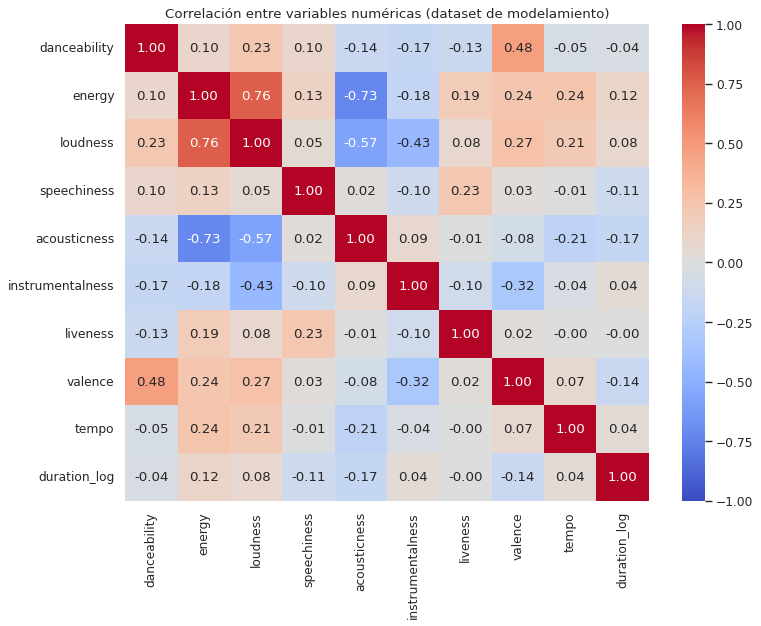

Pares con |r| >= 0,4:
energy        acousticness       -0.73
loudness      acousticness       -0.57
              instrumentalness   -0.43
danceability  valence             0.48
energy        loudness            0.76
dtype: float64


In [4]:
corr = datos[numericas].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas (dataset de modelamiento)")
plt.tight_layout()
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pares con |r| >= 0,4:")
print(pares[pares.abs() >= 0.4].round(2).sort_values())

# 4. Separación de datos y preprocesamiento por modelo

## 4.1 Entrenamiento y prueba

Separamos aleatoriamente el 80 % para **entrenamiento** y el 20 % para **prueba final**. Los hiperparámetros, pruebas de variables y comparaciones con distinta cantidad de datos se realizan **solo dentro del entrenamiento**, mediante validación cruzada o una partición de validación.

El conjunto de prueba final se utiliza para **evaluar los modelos ya ajustados y describir sus errores**. No se decide qué variables conservar ni qué parámetros escoger a partir de él.

In [5]:
X = datos[variables_completas]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Popularidad media en entrenamiento:", round(y_train.mean(), 2), "| en prueba:", round(y_test.mean(), 2))

Entrenamiento: (64188, 15) | Prueba: (16047, 15)
Popularidad media en entrenamiento: 37.05 | en prueba: 37.13


## 4.2 Preprocesamiento: qué necesita cada modelo y por qué

Cada algoritmo funciona distinto, así que no todos necesitan las mismas transformaciones. Todo el preprocesamiento va dentro de un **`Pipeline`**: así el escalador y los codificadores se ajustan **solo con los datos de entrenamiento** de cada partición (también dentro de la validación cruzada) y se aplican igual a los datos nuevos. Esto evita la fuga de información y asegura que una canción nueva reciba exactamente la misma transformación que las de entrenamiento.

| Transformación | Ridge | Random Forest | Gradient Boosting | K-Means |
|---|---|---|---|---|
| `StandardScaler` en numéricas | **Sí** | No | No | **Sí** |
| One-hot en `key`, `time_signature`, `track_genre` | Sí | Sí | No (categorías nativas) | No se usan |
| Logaritmo de la duración | Sí | Sí | Sí | Sí |

**¿Por qué Ridge necesita escalamiento?** Ridge penaliza el tamaño de los coeficientes (`alpha · Σβ²`). Si `tempo` está en BPM (~120) y `danceability` entre 0 y 1, el coeficiente de `tempo` sería naturalmente pequeño y el de `danceability` grande, y la penalización castigaría más a `danceability` solo por su unidad. Al escalar, todas las variables quedan con media 0 y desviación 1 y se penalizan por igual.

**¿Por qué los árboles no lo necesitan?** Un árbol divide con reglas del tipo "`tempo` < 110". Escalar cambia el número del umbral, pero no el orden de las canciones, así que las divisiones y las predicciones son las mismas.

**¿Por qué K-Means sí lo necesita?** Agrupa por **distancia**. Sin escalar, una diferencia de 30 BPM pesaría 100 veces más que una diferencia de 0,3 en `energy`, y los grupos se formarían casi solo por la variable de mayor escala.

**¿Por qué Gradient Boosting usa categorías nativas?** `HistGradientBoostingRegressor` puede tratar una variable categórica directamente y agrupar en cada división los géneros que se parecen, en vez de evaluar 114 columnas por separado. En la prueba inicial esto dio menor error y es mucho más rápido.

In [6]:
def preprocesador_onehot(columnas, escalar):
    num = [c for c in columnas if c in numericas]
    binv = [c for c in columnas if c in binarias]
    cat = [c for c in columnas if c in categoricas_audio + genero]
    transformaciones = [("num", StandardScaler() if escalar else "passthrough", num),
                        ("bin", "passthrough", binv)]
    if cat:
        transformaciones.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(transformaciones)


def preprocesador_ordinal(columnas):
    num = [c for c in columnas if c in numericas + binarias]
    cat = [c for c in columnas if c in categoricas_audio + genero]
    transformaciones = [("num", "passthrough", num)]
    if cat:
        transformaciones.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat))
    mascara = [False] * len(num) + [True] * len(cat)
    return ColumnTransformer(transformaciones), mascara


def crear_ridge(columnas, alpha=1.0):
    return Pipeline([("prep", preprocesador_onehot(columnas, escalar=True)),
                     ("modelo", Ridge(alpha=alpha))])


def crear_bosque(columnas, n_estimators=100, min_samples_leaf=5, max_features=0.33):
    return Pipeline([("prep", preprocesador_onehot(columnas, escalar=False)),
                     ("modelo", RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                                                      max_features=max_features, n_jobs=-1, random_state=SEMILLA))])


def crear_boosting(columnas, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20):
    prep, mascara = preprocesador_ordinal(columnas)
    return Pipeline([("prep", prep),
                     ("modelo", HistGradientBoostingRegressor(
                         learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                         min_samples_leaf=min_samples_leaf, max_iter=1000, early_stopping=True,
                         validation_fraction=0.1, n_iter_no_change=30,
                         categorical_features=mascara, random_state=SEMILLA))])

# 5. Métricas y modelos de referencia

## 5.1 Las métricas dependen del problema, no del algoritmo

Los tres modelos supervisados predicen un número, por lo que los comparamos con las **mismas métricas**:

| Métrica | Qué significa | Uso |
|---|---|---|
| **MAE** | Error absoluto medio, en puntos | **Principal**: comprensible para el sello |
| **RMSE** | Raíz del error cuadrático medio | Detecta el impacto de errores grandes |
| **R²** | Variación explicada comparada con predecir la media | Apoyo para interpretar el ajuste |
| **R² ajustado** | R² penalizado por la cantidad de variables | **Secundario**: confirma que la mejora no se debe solo a tener 142 columnas |
| **Precisión del top 10 %** | Qué proporción de las canciones priorizadas tiene popularidad ≥ 50 | Evaluación complementaria de la decisión comercial |

**R² frente a R² ajustado:** el R² siempre sube (o se mantiene) al agregar variables, aunque no aporten. Como los modelos usan 142 columnas, un R² alto podría deberse solo a la cantidad de columnas. El **R² ajustado** descuenta el número de predictores:

$$R^2_{aj} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1}$$

Con n = 16.047 canciones de prueba y p = 142, el factor de penalización es 1,0089. Lo usamos como **criterio secundario** (meta > 0,431, el valor de la regla por género). Advertencia: la fórmula supone un modelo lineal con p coeficientes; en Random Forest y Gradient Boosting el número de columnas no refleja toda su complejidad (cantidad de árboles y divisiones), así que para ellos es aproximado. Por eso **la elección entre modelos se hace con el MAE de validación**, y el R² ajustado confirma que la mejora no se debe solo a la cantidad de variables.

En K-Means no existe una respuesta correcta conocida; usamos **inercia, silueta y Davies-Bouldin** para evaluar compacidad y separación. En PCA medimos el **porcentaje de varianza explicada** y, para comparar K-Means con el agrupamiento jerárquico, el **índice de Rand ajustado** (0 = acuerdo al azar, 1 = mismos grupos).

## 5.2 Referencias sencillas

1. **Promedio general:** siempre la media de popularidad del conjunto de entrenamiento.
2. **Promedio del género:** la popularidad media de ese género, calculada solo en entrenamiento. Es una referencia exigente que no requiere algoritmos de ML.


In [7]:
n_test = len(y_test)

# Criterio secundario (meta de la EP1). En árboles su penalización es aproximada: se elige por MAE.
def r2_ajustado(r2, p, n=n_test):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def precision_top10(pred, real=y_test):
    pred = pd.Series(np.asarray(pred), index=real.index)
    top = pred.nlargest(int(len(pred) * 0.10)).index
    return (real.loc[top] >= 50).mean()

def evaluar(nombre, pred, p):
    r2 = r2_score(y_test, pred)
    return {"Modelo": nombre,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2,
            "R2 ajustado": r2_ajustado(r2, p),
            "Precisión top 10 %": precision_top10(pred)}

pred_media = np.full(n_test, y_train.mean())
promedio_genero = y_train.groupby(X_train["track_genre"]).mean()
pred_genero = X_test["track_genre"].map(promedio_genero).values

referencias = pd.DataFrame([
    evaluar("Referencia: promedio general", pred_media, 0),
    evaluar("Referencia: promedio del género", pred_genero, datos["track_genre"].nunique() - 1),
])
print("Proporción de canciones de alto potencial en prueba:", round((y_test >= 50).mean(), 3))
referencias.round(3)

Proporción de canciones de alto potencial en prueba: 0.265


,Modelo,MAE,RMSE,R2,R2 ajustado,Precisión top 10 %
0,Referencia: promedio general,15.192,18.181,-0.000,-0.000,0.256
1,Referencia: promedio del género,9.881,13.669,0.435,0.431,0.756


La regla por género logra en prueba **MAE 9,881**, R² ajustado 0,431 y **precisión de 75,6 %** en el top 10 % (frente a 26,5 % de canciones de alto potencial en toda la prueba). Son las mismas cifras de la EP1, porque usamos la misma partición. La regla sirve como **referencia**, no como criterio para escoger hiperparámetros.

**Decisión técnica:** se prioriza un menor **MAE de validación** y se contrasta después con RMSE, R², precisión del top 10 %, tiempo de ejecución y utilidad para el negocio.

# 6. Modelos supervisados

## 6.1 Justificación de los tres algoritmos

| Modelo | Cómo funciona | Por qué lo elegimos para este caso |
|---|---|---|
| **Ridge** | Regresión lineal con penalización L2 sobre los coeficientes | Es el modelo base interpretable. La penalización controla la multicolinealidad entre `energy`, `loudness` y `acousticness` y la gran cantidad de columnas one-hot. Si un modelo más complejo no lo supera claramente, preferimos el simple |
| **Random Forest** | Promedio de muchos árboles entrenados con muestras y variables al azar | En la EP1 encontramos relaciones **no lineales** (forma de "U invertida" en `energy`, `acousticness`, `danceability`, `valence` y duración). Los árboles las capturan sin que tengamos que definir la forma, también capturan interacciones (por ejemplo, que `energy` importe distinto según el género) y son robustos a los atípicos que decidimos mantener |
| **Gradient Boosting** (`HistGradientBoostingRegressor`) | Árboles pequeños en secuencia: cada uno corrige los errores de los anteriores | Captura lo mismo que Random Forest, pero suele lograr menor error con datos tabulares, es mucho más rápido y maneja el género como categoría nativa |

Los tres cubren desde lo más simple e interpretable (lineal) hasta lo más flexible (boosting), para poder responder si la complejidad adicional se justifica.

## 6.2 Ajuste de hiperparámetros

Los hiperparámetros se eligen **solo con el entrenamiento**:

- **Ridge y Gradient Boosting:** validación cruzada de 5 particiones (`GridSearchCV`), con el MAE como criterio.
- **Random Forest:** por su tiempo de entrenamiento (cerca de un minuto por ajuste), usamos una **partición de validación** del 20 % del entrenamiento.

**Por qué probamos esos hiperparámetros:**

- En **Ridge**, `alpha` controla cuánto se reducen los coeficientes; comparamos valores pequeños y grandes para buscar equilibrio entre ajuste y penalización.
- En **Random Forest**, `min_samples_leaf` controla cuántas canciones necesita una hoja (ayuda a limitar sobreajuste) y `max_features` controla cuántos predictores se consideran en cada división (aporta diversidad a los árboles).
- En **Gradient Boosting**, `learning_rate` controla el aporte de cada árbol, `max_leaf_nodes` limita su complejidad y `min_samples_leaf` evita divisiones con muestras demasiado pequeñas.

Se ajustan usando **MAE de validación** porque el problema es de regresión y necesitamos minimizar el error en puntos de popularidad.

In [8]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

inicio = time.time()
busqueda_ridge = GridSearchCV(crear_ridge(variables_completas),
                              {"modelo__alpha": [0.1, 1, 10, 100, 1000]},
                              cv=cv5, scoring="neg_mean_absolute_error", n_jobs=-1)
busqueda_ridge.fit(X_train, y_train)
tabla_ridge = pd.DataFrame(busqueda_ridge.cv_results_)[["param_modelo__alpha", "mean_test_score", "std_test_score"]]
tabla_ridge.columns = ["alpha", "MAE CV", "desv. CV"]
tabla_ridge["MAE CV"] = -tabla_ridge["MAE CV"]
print("Ridge - mejor alpha:", busqueda_ridge.best_params_["modelo__alpha"], f"({time.time() - inicio:.0f} s)")
tabla_ridge.round(3)

Ridge - mejor alpha: 0.1 (7 s)


,alpha,MAE CV,desv. CV
0,0.1,9.718,0.073
1,1.0,9.723,0.073
2,10.0,9.767,0.074
3,100.0,10.242,0.076
4,1000.0,12.500,0.093


In [9]:
inicio = time.time()
busqueda_boosting = GridSearchCV(crear_boosting(variables_completas),
                                 {"modelo__learning_rate": [0.05, 0.1],
                                  "modelo__max_leaf_nodes": [15, 31, 63],
                                  "modelo__min_samples_leaf": [20, 50]},
                                 cv=cv5, scoring="neg_mean_absolute_error", n_jobs=-1)
busqueda_boosting.fit(X_train, y_train)
tabla_boosting = pd.DataFrame(busqueda_boosting.cv_results_)
tabla_boosting = tabla_boosting[["param_modelo__learning_rate", "param_modelo__max_leaf_nodes",
                                 "param_modelo__min_samples_leaf", "mean_test_score", "std_test_score"]]
tabla_boosting.columns = ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "MAE CV", "desv. CV"]
tabla_boosting["MAE CV"] = -tabla_boosting["MAE CV"]
print("Gradient Boosting - mejores parámetros:", busqueda_boosting.best_params_, f"({time.time() - inicio:.0f} s)")
tabla_boosting.sort_values("MAE CV").round(3)

Gradient Boosting - mejores parámetros: {'modelo__learning_rate': 0.05, 'modelo__max_leaf_nodes': 63, 'modelo__min_samples_leaf': 20} (147 s)


,learning_rate,max_leaf_nodes,min_samples_leaf,MAE CV,desv. CV
4,0.05,63,20,8.957,0.079
10,0.10,63,20,8.961,0.082
5,0.05,63,50,8.978,0.099
2,0.05,31,20,8.991,0.078
11,0.10,63,50,8.999,0.094
3,0.05,31,50,9.004,0.082
9,0.10,31,50,9.015,0.079
6,0.10,15,20,9.024,0.071
8,0.10,31,20,9.029,0.081
0,0.05,15,20,9.049,0.100


In [10]:
X_ajuste, X_valid, y_ajuste, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=SEMILLA)

inicio = time.time()
resultados_bosque = []
for hoja in [2, 5, 10]:
    for max_feat in [0.33, 0.5]:
        bosque = crear_bosque(variables_completas, n_estimators=60, min_samples_leaf=hoja, max_features=max_feat)
        bosque.fit(X_ajuste, y_ajuste)
        resultados_bosque.append({"min_samples_leaf": hoja, "max_features": max_feat,
                                  "MAE validación": mean_absolute_error(y_valid, bosque.predict(X_valid))})
tabla_bosque = pd.DataFrame(resultados_bosque).sort_values("MAE validación")
mejor_bosque = tabla_bosque.iloc[0]
print(f"Random Forest - mejor configuración: min_samples_leaf={int(mejor_bosque['min_samples_leaf'])}, "
      f"max_features={mejor_bosque['max_features']} ({time.time() - inicio:.0f} s)")
tabla_bosque.round(3)

Random Forest - mejor configuración: min_samples_leaf=2, max_features=0.5 (349 s)


,min_samples_leaf,max_features,MAE validación
1,2,0.50,9.181
0,2,0.33,9.196
3,5,0.50,9.198
2,5,0.33,9.283
5,10,0.50,9.320
4,10,0.33,9.392


## 6.2.1 Comparación de los tres modelos con la misma validación

Ridge y Gradient Boosting se ajustaron con validación cruzada y Random Forest con una partición de validación, así que sus MAE de ajuste **no se pueden comparar directamente**. Para elegir el algoritmo **sin consultar la prueba final**, entrenamos los tres con sus mejores hiperparámetros sobre la misma parte de ajuste (`X_ajuste`, 80 % del entrenamiento) y los evaluamos sobre la misma validación (`X_valid`, 20 % del entrenamiento). También calculamos la regla por género y la precisión del top 10 % en esa validación.


In [11]:
params_ridge = busqueda_ridge.best_params_["modelo__alpha"]
params_gb = {k.replace("modelo__", ""): v for k, v in busqueda_boosting.best_params_.items()}
candidatos = {
    "Ridge": crear_ridge(variables_completas, params_ridge),
    "Random Forest (60 árboles)": crear_bosque(variables_completas, n_estimators=60,
                                               min_samples_leaf=int(mejor_bosque["min_samples_leaf"]),
                                               max_features=mejor_bosque["max_features"]),
    "Gradient Boosting": crear_boosting(variables_completas, **params_gb),
}
media_genero_ajuste = y_ajuste.groupby(X_ajuste["track_genre"]).mean()
pred_regla_valid = X_valid["track_genre"].map(media_genero_ajuste).fillna(y_ajuste.mean())
filas_valid = [{"Modelo": "Regla por género", "MAE validación": mean_absolute_error(y_valid, pred_regla_valid),
                "Precisión top 10 % (validación)": precision_top10(pred_regla_valid, real=y_valid)}]
for nombre, modelo in candidatos.items():
    pred_v = modelo.fit(X_ajuste, y_ajuste).predict(X_valid)
    filas_valid.append({"Modelo": nombre, "MAE validación": mean_absolute_error(y_valid, pred_v),
                        "Precisión top 10 % (validación)": precision_top10(pred_v, real=y_valid)})
misma_validacion = pd.DataFrame(filas_valid)
misma_validacion.round(3)


,Modelo,MAE validación,Precisión top 10 % (validación)
0,Regla por género,9.702,0.747
1,Ridge,9.653,0.751
2,Random Forest (60 árboles),9.181,0.804
3,Gradient Boosting,8.881,0.795


**Resultados del ajuste:**

- **Ridge:** el mejor `alpha` es 0,1 (MAE CV 9,718), prácticamente igual a `alpha` = 1 (9,723). Con `alpha` ≥ 100 el error sube claramente (hasta 12,50 con 1.000), porque una penalización muy fuerte "aplana" los coeficientes del género y el modelo pierde su variable más informativa. Un `alpha` bajo indica que, con 64.188 canciones, el modelo no tiene problemas de sobreajuste.
- **Gradient Boosting:** la mejor combinación es `learning_rate` = 0,05, `max_leaf_nodes` = 63 y `min_samples_leaf` = 20 (MAE CV 8,957 ± 0,079). Las 12 combinaciones quedan entre 8,96 y 9,06, así que el modelo es **poco sensible** a estos parámetros: las tres mejores difieren en solo 0,02 puntos. Lo que más ayuda es permitir árboles con más hojas (63), que pueden representar más combinaciones de género y audio.
- **Random Forest:** la mejor configuración es `min_samples_leaf` = 2 y `max_features` = 0,5 (MAE de validación 9,181). Hojas más pequeñas y más variables por división le permiten capturar más detalle.

**Comparación con la misma validación (sección 6.2.1):** con la misma partición, Gradient Boosting obtiene **MAE 8,881**, Random Forest 9,181, Ridge 9,653 y la regla por género 9,702. En precisión del top 10 %, Random Forest queda levemente arriba (80,4 % frente a 79,5 %), y ambos superan a la regla (74,7 %). **Con esta evidencia de validación elegimos Gradient Boosting antes de mirar la prueba final**: tiene el menor error, unos 0,3 puntos menos que Random Forest, y entrena mucho más rápido.

Las desviaciones entre particiones (0,07 a 0,10 puntos) son mucho menores que las diferencias entre modelos, lo que indica que la comparación es confiable.

## 6.3 Entrenamiento final y comparación en prueba

Después de elegir hiperparámetros con entrenamiento/validación, entrenamos los tres modelos sobre **todo el entrenamiento**. El conjunto de prueba final se utiliza para **comparar resultados y analizar errores**, pero **no** para seleccionar variables o reajustar modelos. La selección principal de Gradient Boosting se plantea por sus resultados de validación y facilidad operativa; la prueba verifica si esa elección se sostiene.

In [12]:
p_completo = len(busqueda_ridge.best_estimator_.named_steps["prep"].get_feature_names_out())

modelos = {
    "Ridge": busqueda_ridge.best_estimator_,
    "Random Forest": crear_bosque(variables_completas, n_estimators=200,
                                  min_samples_leaf=int(mejor_bosque["min_samples_leaf"]),
                                  max_features=mejor_bosque["max_features"]),
    "Gradient Boosting": busqueda_boosting.best_estimator_,
}

predicciones = {}
filas = []
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train, y_train)  # se reentrena para medir el tiempo de entrenamiento
    predicciones[nombre] = modelo.predict(X_test)
    fila = evaluar(nombre, predicciones[nombre], p_completo)
    fila["Tiempo entrenamiento (s)"] = time.time() - inicio
    filas.append(fila)

comparacion = pd.concat([referencias, pd.DataFrame(filas)], ignore_index=True)
comparacion["Cumple MAE < 9,88"] = comparacion["MAE"] < 9.88
comparacion["Cumple R2 aj. > 0,431"] = comparacion["R2 ajustado"] > 0.431
comparacion["Supera precisión de la regla"] = comparacion["Precisión top 10 %"] > referencias.loc[1, "Precisión top 10 %"]
print("Variables después del preprocesamiento (p):", p_completo)
comparacion.round(3)

Variables después del preprocesamiento (p): 142


,Modelo,MAE,RMSE,R2,R2 ajustado,Precisión top 10 %,Tiempo entrenamiento (s),"Cumple MAE < 9,88","Cumple R2 aj. > 0,431",Supera precisión de la regla
0,Referencia: promedio general,15.192,18.181,-0.000,-0.000,0.256,NaN,False,False,False
1,Referencia: promedio del género,9.881,13.669,0.435,0.431,0.756,NaN,False,False,False
2,Ridge,9.804,13.578,0.442,0.437,0.754,1.035,True,True,False
3,Random Forest,9.124,12.996,0.489,0.484,0.810,319.079,True,True,True
4,Gradient Boosting,9.060,12.970,0.491,0.486,0.805,2.537,True,True,True


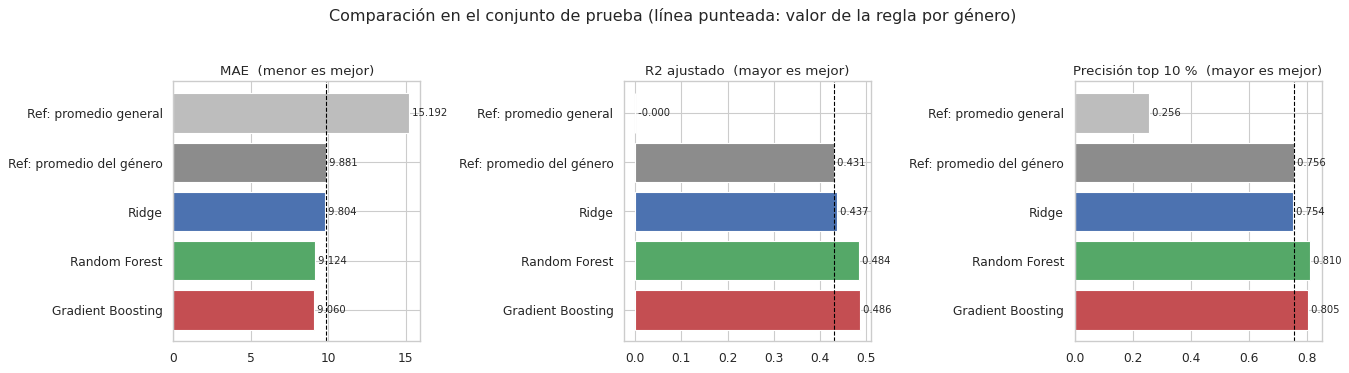

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
orden = comparacion["Modelo"].str.replace("Referencia: ", "Ref: ")
colores = ["#bdbdbd", "#8c8c8c", "#4C72B0", "#55A868", "#C44E52"]
for eje, metrica, meta in zip(ejes, ["MAE", "R2 ajustado", "Precisión top 10 %"], [9.88, 0.431, referencias.loc[1, "Precisión top 10 %"]]):
    eje.barh(orden, comparacion[metrica], color=colores)
    eje.axvline(meta, color="black", linestyle="--", linewidth=1)
    eje.set_title(metrica + ("  (menor es mejor)" if metrica == "MAE" else "  (mayor es mejor)"))
    for i, v in enumerate(comparacion[metrica]):
        eje.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ejes[0].invert_yaxis(); ejes[1].invert_yaxis(); ejes[2].invert_yaxis()
plt.suptitle("Comparación en el conjunto de prueba (línea punteada: valor de la regla por género)", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_comparacion_modelos.png"), bbox_inches="tight")
plt.show()

**Resultados en la prueba final (16.047 canciones):**

| Modelo | MAE | RMSE | R² | R² ajustado (> 0,431) | Precisión top 10 % |
|---|---:|---:|---:|---:|---:|
| Promedio general | 15,192 | 18,181 | 0,000 | 0,000 | 25,6 % |
| Promedio por género | 9,881 | 13,669 | 0,435 | 0,431 | 75,6 % |
| Ridge | 9,804 | 13,578 | 0,442 | 0,437 | 75,4 % |
| Random Forest | 9,124 | 12,996 | 0,489 | 0,484 | **81,0 %** |
| **Gradient Boosting** | **9,060** | **12,970** | **0,491** | **0,486** | 80,5 % |

- **La prueba confirma la elección hecha con validación:** Gradient Boosting tiene el menor MAE y RMSE.
- **Ridge** casi no mejora a la regla por género (0,08 puntos de MAE) y queda por debajo en precisión. Un modelo lineal suma un efecto fijo por género más un efecto lineal por cada variable de audio, y en la EP1 vimos que el audio se relaciona con la popularidad en forma **curva**.
- **Random Forest y Gradient Boosting** reducen el MAE en 0,76 y 0,82 puntos frente a la regla (8 %), y Gradient Boosting lo reduce en un 40 % frente al promedio general (de 15,19 a 9,06). Las relaciones no lineales y las interacciones entre género y audio contienen información que los árboles sí aprovechan.
- **RMSE frente a MAE:** en todos los modelos el RMSE (~13) es bastante mayor que el MAE (~9), señal de que hay canciones con errores grandes (sección 8.2).
- **Precisión:** de las 1.604 canciones que Gradient Boosting pone más arriba, el 80,5 % es de alto potencial, frente al 26,5 % que se obtendría al azar: **3 veces mejor que el azar** y 5 puntos mejor que elegir por género.

- **R² ajustado (criterio secundario):** los tres modelos superan 0,431, y Gradient Boosting llega a 0,486. Con 142 columnas la penalización baja el R² en apenas 0,005 puntos, así que la mejora no se explica por la cantidad de variables. En los árboles es una medida aproximada (sección 5.1), por lo que confirma, pero no decide, la elección.

 La popularidad no depende únicamente del audio: influyen factores que no están en el dataset, como campañas, reproducción reciente y trayectoria de los artistas.

# 7. Pruebas con distintas variables y datos

Buscamos entender **qué aporta cada conjunto de variables** y cuánto cambian las métricas. Usamos **las mismas particiones de validación** para hacer comparaciones justas, todas dentro de los datos de entrenamiento.

También mostramos un **valor p orientativo** mediante prueba t pareada de los cinco MAE. **Importante:** los entrenamientos de validación cruzada se solapan; sus resultados no son completamente independientes. Por eso ese valor p **no demuestra por sí solo significancia estadística concluyente**. Miramos principalmente el cambio promedio en MAE: una diferencia de 0,01 puntos puede carecer de importancia práctica.

## 7.1 ¿Qué aporta cada grupo de variables?

**Regla de comparación:** seleccionamos parámetros con entrenamiento y validación. Reservamos la prueba final para la comparación de desempeño. Las diferencias de MAE de validación indican el tamaño del efecto; los valores p de cinco folds se consideran orientativos debido al solapamiento entre entrenamientos.

In [14]:
cv_por_config = {}

def mae_cv(modelo, columnas, X_base=X_train, y_base=y_train):
    return -cross_val_score(modelo, X_base[columnas], y_base, cv=cv5,
                            scoring="neg_mean_absolute_error", n_jobs=-1)

conjuntos = {
    "Solo audio (14 variables)": variables_audio,
    "Solo género": genero,
    "Audio + género (15 variables)": variables_completas,
}
alpha = busqueda_ridge.best_params_["modelo__alpha"]
params_boosting = {k.replace("modelo__", ""): v for k, v in busqueda_boosting.best_params_.items()}

filas = []
for nombre_conjunto, columnas in conjuntos.items():
    for nombre_modelo, modelo in [("Ridge", crear_ridge(columnas, alpha)),
                                  ("Gradient Boosting", crear_boosting(columnas, **params_boosting))]:
        maes = mae_cv(modelo, columnas)
        cv_por_config[(nombre_modelo, nombre_conjunto)] = maes
        filas.append({"Modelo": nombre_modelo, "Variables": nombre_conjunto,
                      "MAE CV medio": maes.mean(), "desv.": maes.std()})

experimento_variables = pd.DataFrame(filas)
experimento_variables.round(3)

,Modelo,Variables,MAE CV medio,desv.
0,Ridge,Solo audio (14 variables),14.369,0.108
1,Gradient Boosting,Solo audio (14 variables),13.039,0.121
2,Ridge,Solo género,9.774,0.078
3,Gradient Boosting,Solo género,9.778,0.078
4,Ridge,Audio + género (15 variables),9.718,0.073
5,Gradient Boosting,Audio + género (15 variables),8.957,0.079


In [15]:
# Comparación exploratoria: mismas particiones para cada par de configuraciones.
def comparar(a, b):
    _, p = stats.ttest_rel(cv_por_config[a], cv_por_config[b])
    dif = (cv_por_config[b] - cv_por_config[a]).mean()
    return {"Configuración A": " | ".join(a), "Configuración B": " | ".join(b),
            "MAE B - MAE A": dif,
            "valor p (orientativo)": p,
            "Diferencia >= 0,20 pts": "Sí" if abs(dif) >= 0.2 else "No"}

pruebas = pd.DataFrame([
    comparar(("Gradient Boosting", "Audio + género (15 variables)"), ("Gradient Boosting", "Solo audio (14 variables)")),
    comparar(("Gradient Boosting", "Audio + género (15 variables)"), ("Gradient Boosting", "Solo género")),
    comparar(("Ridge", "Audio + género (15 variables)"), ("Ridge", "Solo género")),
    comparar(("Gradient Boosting", "Audio + género (15 variables)"), ("Ridge", "Audio + género (15 variables)")),
])
pruebas.round(4)

,Configuración A,Configuración B,MAE B - MAE A,valor p (orientativo),"Diferencia >= 0,20 pts"
0,Gradient Boosting | Audio + género (15 variables),Gradient Boosting | Solo audio (14 variables),4.0824,0.0000,Sí
1,Gradient Boosting | Audio + género (15 variables),Gradient Boosting | Solo género,0.8211,0.0000,Sí
2,Ridge | Audio + género (15 variables),Ridge | Solo género,0.0559,0.0002,No
3,Gradient Boosting | Audio + género (15 variables),Ridge | Audio + género (15 variables),0.7613,0.0000,Sí


**Resultados:**

| Conjunto de variables | Ridge (MAE CV) | Gradient Boosting (MAE CV) |
|---|---|---|
| Solo audio | 14,369 | 13,039 |
| Solo género | 9,774 | 9,778 |
| Audio + género | 9,718 | **8,957** |

1. **El género es la variable más informativa.** Usar solo el audio deja el MAE en 13,0, mientras que solo el género lo baja a 9,8. Agregar el género al audio reduce el error en **4,08 puntos** (valor p orientativo < 0,0001).
2. **El audio sí aporta, pero solo a un modelo no lineal.** Con Gradient Boosting, agregar el audio al género baja el MAE de 9,778 a 8,957 (**0,82 puntos**, p < 0,0001). Con Ridge la mejora es de solo 0,06 puntos: con un valor p orientativo pequeño, pero poco relevante en la práctica. Esto muestra que el aporte del audio está en **relaciones curvas e interacciones** (por ejemplo, que una canción muy energética sea popular en un género y no en otro), que una recta no puede representar.
3. **Gradient Boosting supera a Ridge** con las mismas variables en 0,76 puntos (valor p orientativo < 0,0001).

**Diferencia entre evidencia estadística y relevancia práctica:** los valores p calculados con folds solapados son exploratorios; no constituyen pruebas independientes concluyentes. Por eso miramos también el **tamaño** de la diferencia en puntos de popularidad: 0,06 puntos no cambia ninguna decisión del sello; 0,8 o 4 puntos sí.

## 7.2 ¿Qué sucede si incluimos popularidad 0?

La EP1 decidió trabajar únicamente con canciones de popularidad positiva. Para estudiar esa elección, separamos **una validación interna desde el conjunto de entrenamiento** y ajustamos dos versiones de Gradient Boosting:

- Una con canciones de popularidad positiva.
- Otra con esas mismas canciones **más** registros de popularidad 0 que no coinciden con canciones positivas ni con canciones reservadas para prueba.

Las dos se evalúan en la **misma validación interna de canciones positivas**. Esto permite evaluar el efecto sobre **esa población**, pero no probar que todo 0 sea un error ni que convenga excluirlo en todos los usos.

In [16]:
# La evaluación del experimento se hace dentro de entrenamiento, sin usar X_test ni y_test.
X_pos_ajuste, X_pos_valid, y_pos_ajuste, y_pos_valid = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEMILLA)

# Solo añadimos IDs de canciones realmente excluidas por tener popularidad 0.
# Excluir TODOS los IDs de canciones positivas evita que aparezca la misma canción con dos etiquetas.
ids_positivos = set(datos["track_id"])
ceros_extra = con_ceros.loc[(con_ceros["popularity"] == 0) &
                            (~con_ceros["track_id"].isin(ids_positivos))].copy()

positivos_ajuste = datos.loc[X_pos_ajuste.index].copy()
entrenamiento_ampliado = pd.concat([positivos_ajuste, ceros_extra], ignore_index=True)

filas_ceros = []
for nombre, tabla in [("Solo popularidad positiva", positivos_ajuste),
                      ("Positivas + canciones con 0", entrenamiento_ampliado)]:
    modelo_ceros = crear_boosting(variables_completas, **params_boosting)
    modelo_ceros.fit(tabla[variables_completas], tabla["popularity"])
    pred = modelo_ceros.predict(X_pos_valid)
    filas_ceros.append({"Entrenamiento": nombre, "Canciones": len(tabla),
                        "% con popularidad 0": (tabla["popularity"] == 0).mean() * 100,
                        "MAE validación interna": mean_absolute_error(y_pos_valid, pred),
                        "Predicción media": pred.mean(),
                        "Popularidad real media": y_pos_valid.mean()})
resultado_ceros = pd.DataFrame(filas_ceros)
display(resultado_ceros.round(3))

,Entrenamiento,Canciones,% con popularidad 0,MAE validación interna,Predicción media,Popularidad real media
0,Solo popularidad positiva,51350,0.000,8.881,37.090,37.266
1,Positivas + canciones con 0,60693,15.394,9.827,33.847,37.266


**Resultado de la validación interna (51.350 canciones positivas para entrenar):**

- Entrenar solo con canciones positivas: **MAE 8,88**, predicción media 37,1 (real 37,3).
- Agregar **9.343** canciones con popularidad 0 (15,4 % del entrenamiento ampliado): **MAE 9,83**, predicción media 33,8.

En la misma validación de canciones positivas, incluir los ceros empeoró el error unos **0,95 puntos**, pese a aumentar el entrenamiento. La predicción media baja 3,2 puntos: los ceros arrastran todas las estimaciones hacia abajo. Esto **apoya la decisión de la EP1 para el objetivo de predecir popularidad positiva**, pero no demuestra que todos los ceros sean errores ni permite generalizar el resultado a canciones recién publicadas.

## 7.3 ¿Qué pasa al quitar `energy` o al agregar términos cuadráticos en Ridge?

Dos decisiones que vienen de la EP1:

- **Quitar `energy`:** es la variable con mayor VIF (4,24). Si quitarla no cambia el error, es redundante.
- **Agregar términos cuadráticos:** en la EP1 vimos que `energy`, `acousticness`, `danceability` y `valence` tienen forma de "U invertida". Un modelo lineal no puede representar una curva, salvo que le agreguemos la variable al cuadrado.

In [17]:
curvas = ["danceability", "energy", "acousticness", "valence"]

def agregar_cuadrados(X_entrada):
    X_salida = X_entrada.copy()
    for c in curvas:
        X_salida[c + "_2"] = X_salida[c] ** 2
    return X_salida

def crear_ridge_cuadratico(columnas, alpha):
    num = [c for c in columnas if c in numericas] + [c + "_2" for c in curvas]
    prep = ColumnTransformer([("num", StandardScaler(), num), ("bin", "passthrough", binarias),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                               categoricas_audio + genero)])
    return Pipeline([("cuadrados", FunctionTransformer(agregar_cuadrados)), ("prep", prep),
                     ("modelo", Ridge(alpha=alpha))])

sin_energy = [c for c in variables_completas if c != "energy"]
cv_por_config[("Ridge", "Sin energy")] = mae_cv(crear_ridge(sin_energy, alpha), sin_energy)
cv_por_config[("Ridge", "Con términos cuadráticos")] = mae_cv(crear_ridge_cuadratico(variables_completas, alpha),
                                                              variables_completas)
cv_por_config[("Gradient Boosting", "Sin energy")] = mae_cv(crear_boosting(sin_energy, **params_boosting), sin_energy)

pd.DataFrame([
    comparar(("Ridge", "Audio + género (15 variables)"), ("Ridge", "Sin energy")),
    comparar(("Ridge", "Audio + género (15 variables)"), ("Ridge", "Con términos cuadráticos")),
    comparar(("Gradient Boosting", "Audio + género (15 variables)"), ("Gradient Boosting", "Sin energy")),
]).round(4)

,Configuración A,Configuración B,MAE B - MAE A,valor p (orientativo),"Diferencia >= 0,20 pts"
0,Ridge | Audio + género (15 variables),Ridge | Sin energy,0.0135,0.0002,No
1,Ridge | Audio + género (15 variables),Ridge | Con términos cuadráticos,-0.0025,0.3168,No
2,Gradient Boosting | Audio + género (15 variables),Gradient Boosting | Sin energy,0.0412,0.0855,No


**Resultados (MAE de validación cruzada):**

- **Quitar `energy`** empeora el MAE en apenas 0,014 puntos en Ridge y 0,041 en Gradient Boosting. `energy` es en gran parte redundante con `loudness` y `acousticness` (sección 3.2), pero conserva algo de información propia (rango dinámico, timbre, velocidad de los ataques). **Decisión: la mantenemos**, porque quitarla no simplifica el modelo de forma importante y empeora levemente el error. En Ridge la penalización controla la multicolinealidad y en Gradient Boosting no afecta la predicción.
- **Términos cuadráticos en Ridge:** la mejora es de solo 0,003 puntos (valor p orientativo 0,32). Aunque en la EP1 vimos curvas, cada una explicaba menos del 2 % de la variabilidad y la popularidad depende mucho más del género. Para aprovechar el audio no basta con elevar al cuadrado: se necesitan las **interacciones** que capturan los árboles.

Un **valor p pequeño en cinco folds es solo orientativo**. Para el negocio importa cuánto cambia el MAE: diferencias de centésimas no justifican por sí solas más complejidad.

## 7.4 ¿Los resultados son estables ante diferentes divisiones?

Repetimos **cinco divisiones 80/20 únicamente dentro del conjunto de entrenamiento original**. De este modo podemos estimar cuánto varía el MAE de validación según la muestra sin utilizar repetidamente la prueba final reservada. Cada división utiliza exactamente las mismas filas para comparar Ridge, Boosting y la referencia por género.

In [18]:
filas_estabilidad = []
for semilla in [1, 7, 21, 42, 99]:
    Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.2, random_state=semilla)
    media_por_genero = ya.groupby(Xa["track_genre"]).mean()
    regla = Xb["track_genre"].map(media_por_genero).fillna(ya.mean())
    fila = {"Semilla": semilla, "Regla por género": mean_absolute_error(yb, regla)}
    for nombre, modelo in [("Ridge", crear_ridge(variables_completas, alpha)),
                           ("Gradient Boosting", crear_boosting(variables_completas, **params_boosting))]:
        modelo.fit(Xa, ya)
        fila[nombre] = mean_absolute_error(yb, modelo.predict(Xb))
    filas_estabilidad.append(fila)

estabilidad = pd.DataFrame(filas_estabilidad).set_index("Semilla")
display(estabilidad.round(3))
print("Media y desviación del MAE de validación interna:")
display(estabilidad.agg(["mean", "std"]).round(3))

,Regla por género,Ridge,Gradient Boosting
Semilla,,,
1,9.698,9.663,8.922
7,9.731,9.686,8.948
21,9.721,9.664,9.002
42,9.702,9.653,8.881
99,9.788,9.719,8.977


Media y desviación del MAE de validación interna:


,Regla por género,Ridge,Gradient Boosting
mean,9.728,9.677,8.946
std,0.036,0.027,0.047


**Resultados:** en las cinco particiones internas el MAE de Gradient Boosting va de 8,88 a 9,00 (media **8,946 ± 0,047**), el de Ridge de 9,65 a 9,72 (9,677 ± 0,027) y el de la regla por género de 9,70 a 9,79 (9,728 ± 0,036). **El orden es el mismo en las cinco:** Gradient Boosting < Ridge < regla por género. La ventaja de Gradient Boosting sobre la regla (~0,78 puntos) es más de 15 veces la variación entre particiones.

**Limitación:** las divisiones comparten canciones de entrenamiento y, por tanto, no constituyen cinco experimentos independientes. Tampoco garantizan el mismo rendimiento en canciones de otros años o catálogos.

# 8. Interpretación del modelo

## 8.1 ¿Qué variables utiliza?

Usamos **importancia por permutación** como **diagnóstico posterior a la elección del modelo** sobre la prueba final: desordenamos una variable y medimos cuánto empeora el MAE. Así vemos de qué información depende el modelo ya entrenado. **No utilizamos estas importancias para reajustar variables ni hiperparámetros**, porque eso contaminaría la evaluación final.

La importancia por permutación mide **dependencia predictiva, no causalidad**. Además, cuando dos variables están correlacionadas, la importancia puede repartirse entre ambas.

Modelo seleccionado: Gradient Boosting


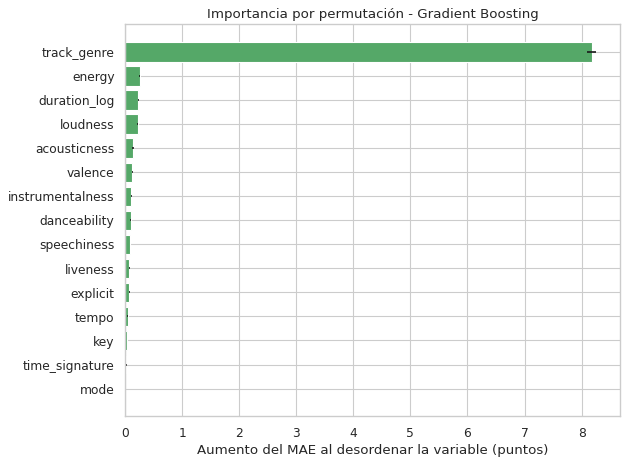

,Variable,Aumento del MAE,desv.
14,track_genre,8.179,0.076
1,energy,0.251,0.010
9,duration_log,0.231,0.007
2,loudness,0.219,0.011
4,acousticness,0.134,0.012
7,valence,0.124,0.005
5,instrumentalness,0.109,0.006
0,danceability,0.097,0.010
3,speechiness,0.086,0.007
6,liveness,0.072,0.007


In [19]:
# Elección fijada ANTES de revisar la prueba final: en la sección 6.2.1 Gradient Boosting tuvo
# el menor MAE en la MISMA partición de validación que Ridge y Random Forest, y es el más rápido de los árboles.
mejor_nombre = "Gradient Boosting"
print("Modelo seleccionado:", mejor_nombre)
modelo_final = modelos[mejor_nombre]

importancia = permutation_importance(modelo_final, X_test, y_test, scoring="neg_mean_absolute_error",
                                     n_repeats=5, random_state=SEMILLA, n_jobs=-1)
tabla_importancia = (pd.DataFrame({"Variable": X_test.columns,
                                   "Aumento del MAE": importancia.importances_mean,
                                   "desv.": importancia.importances_std})
                     .sort_values("Aumento del MAE", ascending=False))

plt.figure(figsize=(8, 6))
plt.barh(tabla_importancia["Variable"], tabla_importancia["Aumento del MAE"],
         xerr=tabla_importancia["desv."], color="#55A868")
plt.gca().invert_yaxis()
plt.xlabel("Aumento del MAE al desordenar la variable (puntos)")
plt.title(f"Importancia por permutación - {mejor_nombre}")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_importancia_variables.png"), bbox_inches="tight")
plt.show()
tabla_importancia.round(3)

**Resultados:**

- **`track_genre` domina:** si se desordena, el MAE sube 8,18 puntos. Ninguna otra variable sube el MAE más de 0,3 puntos.
- Entre las variables de audio, las más usadas son `energy` (0,25), `duration_log` (0,23) y `loudness` (0,22), seguidas por `acousticness`, `valence`, `instrumentalness`, `danceability` y `speechiness` (0,09 a 0,13). Coinciden con las que en la EP1 mostraron relaciones curvas con la popularidad (la duración con su máximo cerca de los 3,5 minutos y `energy` con forma de "U invertida").
- `key`, `time_signature` y `mode` casi no aportan (menos de 0,04). La tonalidad o el compás no cambian la popularidad de forma importante.
- `energy` y `loudness` tienen importancias parecidas: como están correlacionadas, el modelo reparte entre ambas la información de la intensidad.

**Interpretación para el negocio:** el modelo funciona como "**el género define el punto de partida y el sonido ajusta la estimación**". El audio, sumado, es lo que permite mejorar la regla por género en unos 0,8 puntos.

*Nota:* la importancia muestra qué usa el modelo para predecir, **no causas**. Que la duración sea importante no significa que acortar una canción la haga más popular.

## 8.2 ¿Cómo se equivoca el modelo?

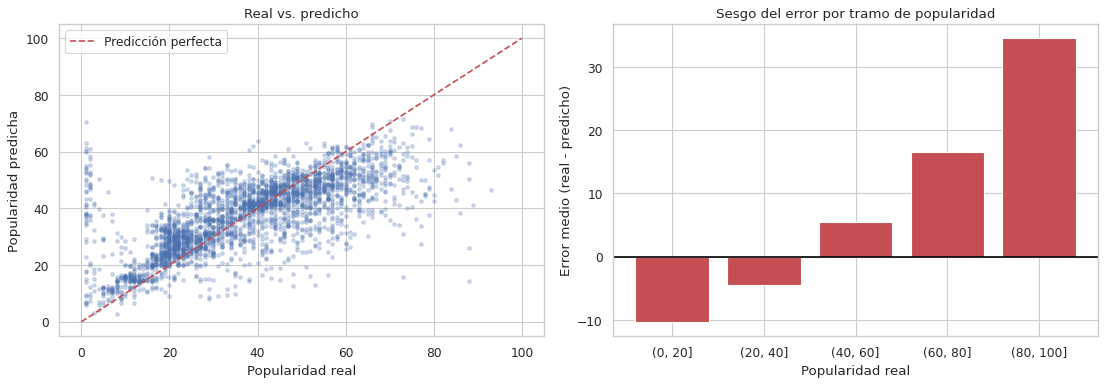

Error medio y MAE por tramo de popularidad real:


,canciones,error medio,MAE
tramo,,,
"(0, 20]",3156,-10.27,10.67
"(20, 40]",5959,-4.49,6.80
"(40, 60]",5128,5.49,7.64
"(60, 80]",1703,16.61,16.73
"(80, 100]",101,34.53,34.53


In [20]:
pred_final = predicciones[mejor_nombre]
residuos = y_test - pred_final

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
muestra = np.random.default_rng(SEMILLA).choice(len(y_test), 3000, replace=False)
ejes[0].scatter(y_test.values[muestra], pred_final[muestra], alpha=0.25, s=10)
ejes[0].plot([0, 100], [0, 100], "r--", label="Predicción perfecta")
ejes[0].set(xlabel="Popularidad real", ylabel="Popularidad predicha", title="Real vs. predicho")
ejes[0].legend()

tramos = pd.cut(y_test, [0, 20, 40, 60, 80, 100])
error_tramo = pd.DataFrame({"tramo": tramos, "error": residuos}).groupby("tramo", observed=True)["error"]
ejes[1].bar(error_tramo.mean().index.astype(str), error_tramo.mean().values, color="#C44E52")
ejes[1].axhline(0, color="black")
ejes[1].set(xlabel="Popularidad real", ylabel="Error medio (real - predicho)",
            title="Sesgo del error por tramo de popularidad")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_errores.png"), bbox_inches="tight")
plt.show()

print("Error medio y MAE por tramo de popularidad real:")
pd.DataFrame({"canciones": error_tramo.size(), "error medio": error_tramo.mean(),
              "MAE": error_tramo.apply(lambda e: e.abs().mean())}).round(2)

**El modelo "tira hacia el centro" (regresión hacia la media):**

| Popularidad real | Canciones | Error medio (real − predicho) | MAE |
|---|---:|---:|---:|
| 1 a 20 | 3.156 | −10,3 (sobreestima) | 10,7 |
| 21 a 40 | 5.959 | −4,5 | 6,8 |
| 41 a 60 | 5.128 | +5,5 | 7,6 |
| 61 a 80 | 1.703 | +16,6 (subestima) | 16,7 |
| 81 a 100 | 101 | +34,5 (subestima) | 34,5 |

- En canciones poco populares (hasta 20) **sobreestima** en promedio 10 puntos.
- En canciones muy populares (61 a 80) **subestima** en 17 puntos, y en los grandes éxitos (81 a 100) en 35 puntos.
- Donde está la mayoría de las canciones (21 a 60) el MAE baja a 6,8-7,6 puntos.

Esto es esperable: el modelo solo ve el género y el sonido, y canciones con el mismo género y un sonido parecido pueden tener popularidades muy distintas según el **artista, la promoción, las playlists y el momento de lanzamiento**, que no están en el dataset. El ejemplo de la sección 10 lo muestra: "INDUSTRY BABY" de Lil Nas X tiene popularidad real 81 y el modelo predice 36, porque su sonido y su género (hip-hop) no explican el efecto de un artista ya famoso.

**Consecuencia para el negocio:** el modelo sirve para **ordenar y priorizar** canciones (por eso su precisión en el top 10 % es alta), pero **no para estimar con exactitud cuán grande será un éxito**. Un valor predicho de 60 debe leerse como "está entre las más prometedoras", no como "llegará exactamente a 60".

## 8.3 Revisión de sesgo: error por género

En la EP1 anticipamos el riesgo de que el modelo dependa del género y funcione distinto según la categoría. Aquí lo medimos.

In [21]:
error_genero = (pd.DataFrame({"género": X_test["track_genre"], "error_abs": residuos.abs(),
                              "error": residuos})
                .groupby("género")
                .agg(canciones=("error_abs", "size"), MAE=("error_abs", "mean"), sesgo=("error", "mean"))
                .sort_values("MAE"))
print("Géneros con menor error:")
display(error_genero.head(5).round(2))
print("Géneros con mayor error:")
display(error_genero.tail(5).round(2))
print("Rango de MAE entre géneros:", round(error_genero["MAE"].min(), 2), "a", round(error_genero["MAE"].max(), 2))
print("Correlación entre la popularidad media del género y el sesgo del error:",
      round(error_genero["sesgo"].corr(y_test.groupby(X_test["track_genre"]).mean()), 3))

Géneros con menor error:


,canciones,MAE,sesgo
género,,,
brazil,127,2.45,-0.02
gospel,151,2.49,0.28
grindcore,196,2.53,-0.08
mpb,141,2.61,-0.09
samba,158,2.76,0.13


Géneros con mayor error:


,canciones,MAE,sesgo
género,,,
reggaeton,63,23.21,5.13
latin,33,25.36,5.17
alternative,58,26.27,1.70
dance,66,32.20,2.81
rock,70,33.71,6.99


Rango de MAE entre géneros: 2.45 a 33.71
Correlación entre la popularidad media del género y el sesgo del error: 0.061


**Resultados:** el error cambia mucho según el género, con MAE desde 2,45 hasta 33,71.

- **Menor error:** `brazil`, `gospel`, `grindcore`, `mpb` y `samba` (MAE 2,5 a 2,8). Son géneros donde casi todas las canciones tienen una popularidad parecida, así que el promedio del género ya es una buena estimación.
- **Mayor error:** `rock` (33,7), `dance` (32,2), `alternative` (26,3), `latin` (25,4) y `reggaeton` (23,2). Son géneros masivos que mezclan grandes éxitos con canciones poco escuchadas: dentro de "rock" hay desde clásicos muy escuchados hasta canciones casi desconocidas, y el sonido no permite distinguirlos. En los cinco el sesgo es positivo (de +1,7 a +7,0): el modelo tiende a **subestimarlos**.
- La correlación entre la popularidad media del género y el sesgo del error es prácticamente 0 (0,06): el modelo **no** favorece de forma sistemática a los géneros populares sobre los poco populares.

**Implicancia ética y de negocio:** en los géneros comerciales más importantes para un sello (rock, dance, latin, reggaeton), el modelo es **menos confiable**. Es justo donde más depende de factores externos al sonido. Por eso recomendamos usarlo como apoyo y no como decisión automática, y revisar con criterio humano las canciones de estos géneros. Además, varios de ellos tienen pocas canciones en prueba (33 a 70), así que su MAE es menos estable.

# 9. Aprendizaje no supervisado: K-Means, PCA y agrupamiento jerárquico

## 9.1 Objetivo y variables

**Pregunta de negocio:** ¿qué perfiles de sonido existen en el catálogo? K-Means agrupa canciones según sus distancias a los centroides. No utiliza popularidad ni género para formar los grupos.

**Variables iniciales:** `danceability`, `energy`, `acousticness`, `instrumentalness`, `valence`, `speechiness` y `duration_log`. Las escalamos porque K-Means trabaja con distancias; sin escalamiento, unidades más grandes dominarían.

- Excluimos `loudness` inicialmente por su redundancia parcial con `energy`: si ambas representan intensidad, esa característica puede quedar sobrerrepresentada.
- Dejamos `tempo` y `liveness` fuera de la configuración inicial para mantener perfiles fáciles de explicar. **No los excluimos por su relación con popularidad**, porque K-Means no predice popularidad. Más adelante **comparamos silueta con y sin estas variables** para comprobar la decisión.
- `track_genre` y `popularity` quedan fuera: se utilizan después para **describir** los grupos, evitando definirlos de antemano por éxito comercial.
- No introducimos códigos como `key` y `time_signature` como distancias numéricas, porque sus números son etiquetas nominales.

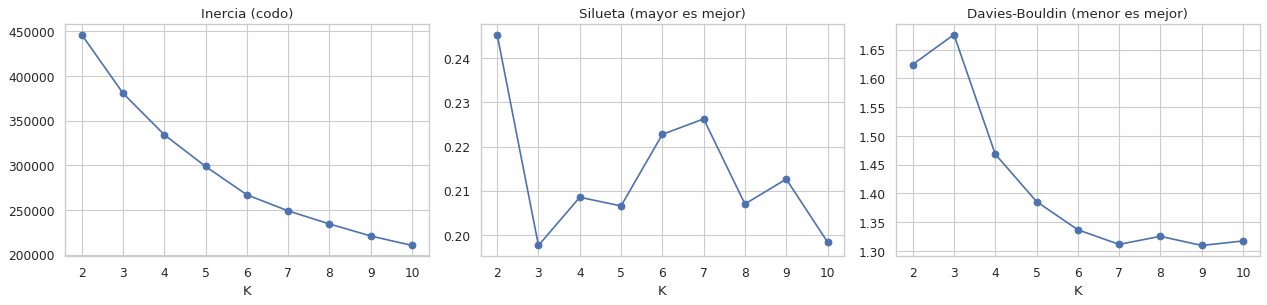

,K,Inercia,Silueta,Davies-Bouldin
0,2,446454.941,0.245,1.624
1,3,380869.792,0.198,1.676
2,4,334394.068,0.209,1.468
3,5,298913.913,0.207,1.386
4,6,267189.049,0.223,1.337
5,7,249200.316,0.226,1.311
6,8,234575.766,0.207,1.325
7,9,221097.076,0.213,1.310
8,10,210516.666,0.198,1.317


In [22]:
variables_cluster = ["danceability", "energy", "acousticness", "instrumentalness",
                     "valence", "speechiness", "duration_log"]
escalador_cluster = StandardScaler()
Z = escalador_cluster.fit_transform(datos[variables_cluster])

rng = np.random.default_rng(SEMILLA)
indices_metricas = rng.choice(len(Z), 10000, replace=False)  # muestra para silueta (es costosa)

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    filas.append({"K": k, "Inercia": km.inertia_,
                  "Silueta": silhouette_score(Z[indices_metricas], km.labels_[indices_metricas]),
                  "Davies-Bouldin": davies_bouldin_score(Z, km.labels_)})
eleccion_k = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, metrica, texto in zip(ejes, ["Inercia", "Silueta", "Davies-Bouldin"],
                               ["(codo)", "(mayor es mejor)", "(menor es mejor)"]):
    eje.plot(eleccion_k["K"], eleccion_k[metrica], marker="o")
    eje.set(title=f"{metrica} {texto}", xlabel="K")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_eleccion_k.png"), bbox_inches="tight")
plt.show()
eleccion_k.round(3)

## 9.1.1 Sensibilidad de los grupos a las variables utilizadas

In [23]:
# Diagnóstico adicional: ¿cambia la calidad del agrupamiento al incluir tempo o liveness?
# Se usa la MISMA muestra de canciones y K=4, para comparar en condiciones equivalentes.
filas_sensibilidad = []
submuestra = datos.sample(n=min(5000, len(datos)), random_state=SEMILLA)
configuraciones_cluster = {
    "7 variables iniciales": variables_cluster,
    "7 variables + tempo": variables_cluster + ["tempo"],
    "7 variables + liveness": variables_cluster + ["liveness"],
}
for nombre, columnas in configuraciones_cluster.items():
    z_sub = StandardScaler().fit_transform(submuestra[columnas])
    km_sub = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit(z_sub)
    sil = silhouette_score(z_sub, km_sub.labels_, sample_size=1500, random_state=SEMILLA)
    db = davies_bouldin_score(z_sub, km_sub.labels_)
    filas_sensibilidad.append({"Variables": nombre, "Silueta (muestra)": sil,
                               "Davies-Bouldin": db})
display(pd.DataFrame(filas_sensibilidad).round(3))

,Variables,Silueta (muestra),Davies-Bouldin
0,7 variables iniciales,0.207,1.467
1,7 variables + tempo,0.176,1.625
2,7 variables + liveness,0.182,1.634


Usamos las **mismas 5.000 canciones**, K = 4 y el mismo escalamiento en tres configuraciones.

| Variables | Silueta de la muestra | Davies-Bouldin |
|---|---:|---:|
| 7 variables iniciales | **0,207** | **1,467** |
| + `tempo` | 0,176 | 1,625 |
| + `liveness` | 0,182 | 1,634 |

La configuración original obtuvo **mejor separación geométrica en esta muestra** (silueta mayor y Davies-Bouldin menor), lo que aporta evidencia para no agregar `tempo` ni `liveness` a K-Means. **No significa que esas variables sean inútiles en otros objetivos o modelos**.

**Elección de K:**

- La **inercia** baja siempre al aumentar K (es esperable: con más grupos cada canción queda más cerca de su centro) y no muestra un codo marcado. La mayor reducción ocurre hasta K = 4-5.
- La **silueta** es más alta con K = 2 (0,245), pero en todos los casos está entre 0,20 y 0,25. Esto indica que los grupos **se solapan**: el sonido de las canciones cambia en forma gradual y no en grupos muy separados.
- **Davies-Bouldin** (mide cuánto se parecen los grupos entre sí; menor es mejor) mejora claramente de K = 3 (1,68) a K = 4 (1,47), y después mejora poco.

**Elegimos K = 4.** Con K = 2 la división solo separa "música acústica" de "música eléctrica", algo obvio que no aporta al negocio. Con K = 4 la silueta casi no cambia (0,209 frente a 0,245), Davies-Bouldin mejora bastante y aparecen perfiles distintos y fáciles de explicar (sección siguiente). Desde K = 5 se agregan grupos más pequeños sin mejoras importantes en las métricas.

Hay que reconocer que con una silueta de ~0,21 los grupos son **perfiles con bordes difusos**, no categorías separadas.

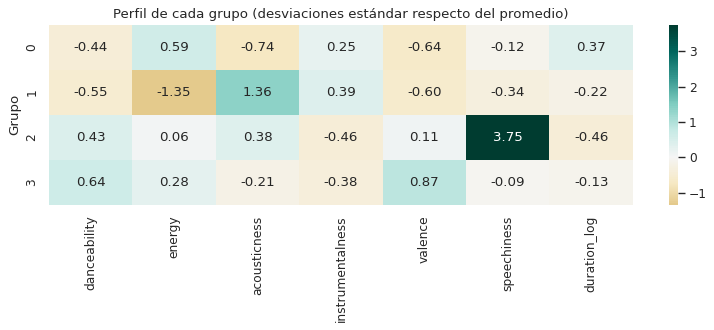

,canciones,popularidad_media,pct_alto_potencial,duracion_min,danceability,energy,acousticness,instrumentalness,valence,speechiness
cluster,,,,,,,,,,
0,26620,35.75,24.83,4.09,0.49,0.79,0.07,0.26,0.30,0.07
1,18436,36.31,26.70,3.35,0.47,0.30,0.78,0.31,0.31,0.05
2,3315,33.23,18.13,3.04,0.64,0.66,0.45,0.03,0.50,0.53
3,31864,38.99,28.41,3.40,0.68,0.71,0.25,0.05,0.70,0.08


In [24]:
K_ELEGIDO = 4
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(Z)
datos["cluster"] = kmeans.labels_

perfil_z = pd.DataFrame(Z, columns=variables_cluster).groupby(kmeans.labels_).mean()
plt.figure(figsize=(10, 0.7 * K_ELEGIDO + 1.5))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="BrBG", center=0)
plt.title("Perfil de cada grupo (desviaciones estándar respecto del promedio)")
plt.ylabel("Grupo")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_perfiles_clusters.png"), bbox_inches="tight")
plt.show()

resumen_clusters = datos.groupby("cluster").agg(
    canciones=("popularity", "size"),
    popularidad_media=("popularity", "mean"),
    pct_alto_potencial=("popularity", lambda s: (s >= 50).mean() * 100),
    duracion_min=("duration_ms", lambda s: (s / 60000).median()),
    **{v: (v, "mean") for v in ["danceability", "energy", "acousticness", "instrumentalness", "valence", "speechiness"]})
resumen_clusters.round(2)

In [25]:
print("Géneros más frecuentes en cada grupo (% de las canciones del grupo):")
for c in range(K_ELEGIDO):
    top = datos.loc[datos["cluster"] == c, "track_genre"].value_counts(normalize=True).head(6) * 100
    print(f"Grupo {c}:", ", ".join(f"{g} ({p:.1f} %)" for g, p in top.items()))

# ¿Qué tan concentrado está cada género en un solo grupo?
concentracion = pd.crosstab(datos["track_genre"], datos["cluster"], normalize="index").max(axis=1)
print()
print("Géneros con más del 80 % de sus canciones en un mismo grupo:", (concentracion > 0.8).sum(), "de",
      len(concentracion))
print("Géneros repartidos (ningún grupo supera el 50 %):", (concentracion < 0.5).sum())

Géneros más frecuentes en cada grupo (% de las canciones del grupo):
Grupo 0: grindcore (3.5 %), black-metal (3.4 %), heavy-metal (3.3 %), drum-and-bass (3.1 %), death-metal (3.0 %), metalcore (2.8 %)
Grupo 1: tango (4.4 %), new-age (4.3 %), opera (4.0 %), disney (3.8 %), ambient (3.7 %), guitar (3.7 %)
Grupo 2: comedy (25.2 %), j-dance (6.9 %), funk (4.5 %), kids (4.1 %), dancehall (3.8 %), french (3.3 %)
Grupo 3: forro (2.7 %), salsa (2.6 %), kids (2.3 %), afrobeat (2.2 %), pagode (2.1 %), sertanejo (2.0 %)

Géneros con más del 80 % de sus canciones en un mismo grupo: 24 de 114
Géneros repartidos (ningún grupo supera el 50 %): 24


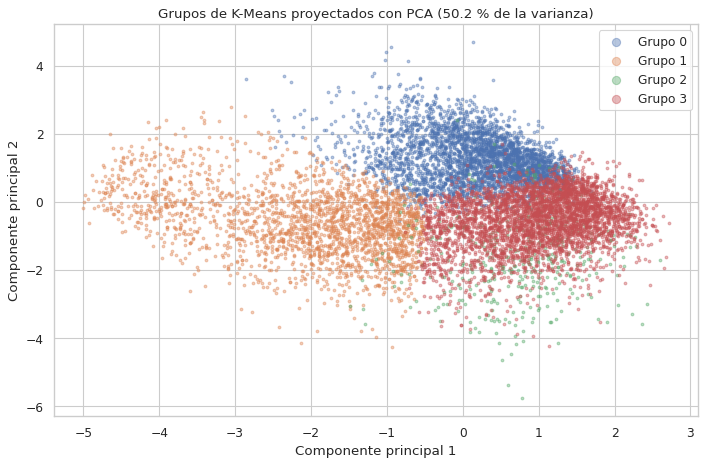

In [26]:
pca = PCA(n_components=2, random_state=SEMILLA)
Z2 = pca.fit_transform(Z[indices_metricas])
plt.figure(figsize=(9, 6))
for c in range(K_ELEGIDO):
    m = kmeans.labels_[indices_metricas] == c
    plt.scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=0.4, label=f"Grupo {c}")
plt.xlabel("Componente principal 1"); plt.ylabel("Componente principal 2")
plt.title(f"Grupos de K-Means proyectados con PCA ({pca.explained_variance_ratio_.sum() * 100:.1f} % de la varianza)")
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_clusters_pca.png"), bbox_inches="tight")
plt.show()

**Los cuatro perfiles de sonido:**

| Grupo | Canciones | Perfil | Rasgos principales | Géneros frecuentes | Popularidad media | % alto potencial |
|---|---|---|---|---|---|---|
| 0 | 26.620 | **Intenso / eléctrico** | `energy` 0,79, `acousticness` 0,07, `valence` baja (0,30), las más largas (4,1 min) | grindcore, black-metal, heavy-metal, drum-and-bass | 35,8 | 24,8 % |
| 1 | 18.436 | **Acústico / tranquilo** | `acousticness` 0,78, `energy` 0,30, más instrumental | tango, new-age, opera, disney, ambient | 36,3 | 26,7 % |
| 2 | 3.315 | **Hablado** | `speechiness` 0,53 (índice elevado de presencia de palabra hablada; **no es un porcentaje de voz**) | comedy (25 %), j-dance, funk, kids, dancehall | 33,2 | 18,1 % |
| 3 | 31.864 | **Bailable / alegre** | `danceability` 0,68, `valence` 0,70, `energy` 0,71 | forro, salsa, afrobeat, pagode, sertanejo | **39,0** | **28,4 %** |

**Hallazgos:**

1. El grupo **bailable/alegre** es el más grande y el de mayor popularidad (39,0; 28,4 % de alto potencial). El **hablado** es el menos popular (33,2; 18,1 %).
2. Las diferencias de popularidad entre grupos son pequeñas (5,8 puntos entre el más y el menos popular), mucho menores que entre géneros. El sonido por sí solo no separa canciones populares de impopulares, lo que coincide con el aprendizaje supervisado.
3. **Los grupos confirman que los géneros se solapan:** solo 24 de 114 géneros tienen más del 80 % de sus canciones en un mismo grupo (por ejemplo, metal en el intenso y música clásica/ambiental en el acústico), y otros 24 géneros están repartidos sin que ningún grupo supere el 50 %. Es decir, para muchos géneros la etiqueta no describe un sonido definido.
4. En la proyección PCA los grupos se ven solapados en los bordes, lo que coincide con la silueta baja. El gráfico muestra solo 2 de las 7 dimensiones (50,7 % de la variación, sección 9.3), así que parte de la separación queda fuera: el perfil hablado se separa en la tercera componente.

**Uso para el negocio:** estos perfiles permiten al sello **organizar el catálogo por sonido** (playlists, campañas, recomendación a medios) en vez de depender de etiquetas de género ambiguas, y priorizar el perfil bailable/alegre, que tiene más canciones de alto potencial.

## 9.2 ¿El grupo de sonido ayuda a predecir la popularidad?

Agregamos el grupo de K-Means como variable a Gradient Boosting y medimos con la misma validación cruzada. Para evitar fuga de información, dentro de cada partición el escalador y K-Means se ajustan **solo** con las canciones de entrenamiento de esa partición.

In [27]:
from sklearn.base import BaseEstimator, TransformerMixin

class AgregarCluster(BaseEstimator, TransformerMixin):
    # Ajusta escalador + K-Means con el entrenamiento y agrega la columna "cluster"
    def __init__(self, k=4):
        self.k = k
    def fit(self, X, y=None):
        self.esc_ = StandardScaler().fit(X[variables_cluster])
        self.km_ = KMeans(n_clusters=self.k, n_init=10, random_state=SEMILLA).fit(self.esc_.transform(X[variables_cluster]))
        return self
    def transform(self, X):
        X = X.copy()
        X["cluster"] = self.km_.predict(self.esc_.transform(X[variables_cluster]))
        return X

def crear_boosting_con_cluster(columnas):
    prep = ColumnTransformer([("num", "passthrough", [c for c in columnas if c in numericas + binarias]),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
                               categoricas_audio + genero + ["cluster"])])
    mascara = [False] * len([c for c in columnas if c in numericas + binarias]) + [True] * 4
    modelo = HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                           n_iter_no_change=30, categorical_features=mascara,
                                           random_state=SEMILLA, **params_boosting)
    return Pipeline([("cluster", AgregarCluster(K_ELEGIDO)), ("prep", prep), ("modelo", modelo)])

columnas_cluster = list(dict.fromkeys(variables_completas + variables_cluster))
cv_por_config[("Gradient Boosting", "Audio + género + grupo K-Means")] = mae_cv(
    crear_boosting_con_cluster(variables_completas), columnas_cluster)
pd.DataFrame([comparar(("Gradient Boosting", "Audio + género (15 variables)"),
                       ("Gradient Boosting", "Audio + género + grupo K-Means"))]).round(4)

,Configuración A,Configuración B,MAE B - MAE A,valor p (orientativo),"Diferencia >= 0,20 pts"
0,Gradient Boosting | Audio + género (15 variables),Gradient Boosting | Audio + género + grupo K-M...,0.0075,0.6171,No


**Resultado:** agregar el grupo de K-Means como variable **no mejora** el modelo: el MAE sube 0,008 puntos (valor p orientativo 0,62). Es lógico: el grupo se construye con las mismas variables de audio que Gradient Boosting ya usa, y el boosting puede formar por su cuenta divisiones más finas que 4 grupos. Por eso **no incluimos el grupo** en el modelo final. Su valor principal está en la **descripción del catálogo** mediante perfiles sonoros.

## 9.3 Análisis de componentes principales (PCA)

PCA es una técnica **no supervisada** que resume variables correlacionadas en componentes nuevas, independientes entre sí y ordenadas por cuánta variación explican. La usamos para responder dos preguntas: **¿cuántas dimensiones de sonido hay realmente en el catálogo?** y **¿qué representa cada eje?** Usamos las mismas 7 variables escaladas de K-Means. Las **cargas** indican cuánto pesa cada variable en una componente: el signo dice en qué dirección y el tamaño, cuánto.

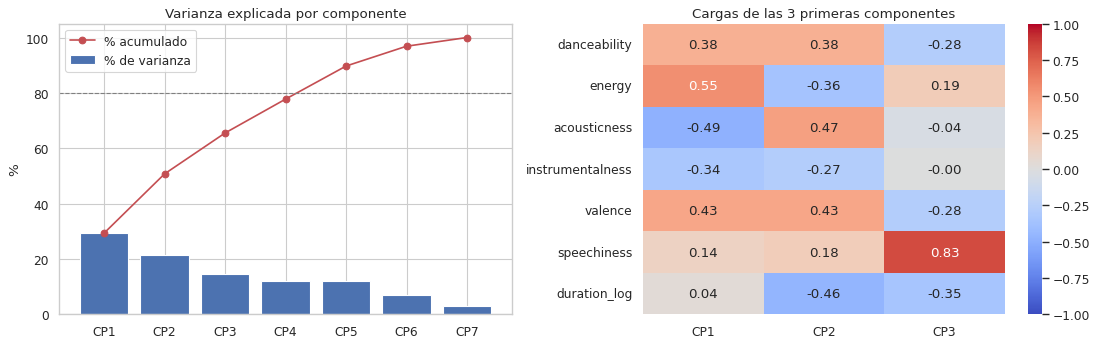

,Componente,% varianza,% acumulado
0,CP1,29.3,29.3
1,CP2,21.4,50.7
2,CP3,14.8,65.5
3,CP4,12.2,77.8
4,CP5,11.9,89.7
5,CP6,7.2,96.9
6,CP7,3.1,100.0


Centro de cada grupo de K-Means en las 3 primeras componentes:


,CP1,CP2,CP3
Grupo K-Means,,,
0,0.16,-1.26,0.21
1,-2.06,0.59,-0.20
2,0.71,1.39,3.12
3,0.98,0.57,-0.39


In [28]:
# PCA con las 7 variables de sonido ya escaladas (Z), sobre las 80.235 canciones.
pca_completo = PCA(random_state=SEMILLA).fit(Z)
varianza = pd.DataFrame({"Componente": [f"CP{i + 1}" for i in range(len(variables_cluster))],
                         "% varianza": pca_completo.explained_variance_ratio_ * 100,
                         "% acumulado": np.cumsum(pca_completo.explained_variance_ratio_) * 100})
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=variables_cluster, columns=["CP1", "CP2", "CP3"])
centros_cp = pd.DataFrame(pca_completo.transform(kmeans.cluster_centers_)[:, :3], columns=["CP1", "CP2", "CP3"])
centros_cp.index.name = "Grupo K-Means"

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].bar(varianza["Componente"], varianza["% varianza"], color="#4C72B0", label="% de varianza")
ejes[0].plot(varianza["Componente"], varianza["% acumulado"], "o-", color="#C44E52", label="% acumulado")
ejes[0].axhline(80, linestyle="--", color="gray", linewidth=1)
ejes[0].set(title="Varianza explicada por componente", ylabel="%")
ejes[0].legend()
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ejes[1])
ejes[1].set_title("Cargas de las 3 primeras componentes")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_pca_componentes.png"), bbox_inches="tight")
plt.show()

display(varianza.round(1))
print("Centro de cada grupo de K-Means en las 3 primeras componentes:")
display(centros_cp.round(2))

**Resultados:**

| Componente | % de varianza | % acumulado | Variables con más peso | Interpretación |
|---|---:|---:|---|---|
| CP1 | 29,3 | 29,3 | `energy` (+0,55), `acousticness` (−0,49), `valence` (+0,43), `danceability` (+0,38), `instrumentalness` (−0,34) | **Eléctrico y alegre ↔ acústico e instrumental** |
| CP2 | 21,4 | 50,7 | `acousticness` (+0,47), `duration_log` (−0,46), `valence` (+0,43), `danceability` (+0,38), `energy` (−0,36) | **Corto, bailable y alegre ↔ largo, intenso e instrumental** |
| CP3 | 14,8 | 65,5 | `speechiness` (+0,83), `duration_log` (−0,35) | **Hablado ↔ cantado** |

- **El sonido tiene varias dimensiones reales.** Dos componentes explican solo el 50,7 % de la variación y se necesitan 4 para llegar al 78 % y 5 para casi el 90 %. Salvo la intensidad (`energy` frente a `acousticness`), las variables no se repiten entre sí, así que **no conviene reemplazar las 7 variables por 2 componentes** en K-Means: se perdería la mitad de la información.
- **Los cuatro perfiles de K-Means son los extremos de estos ejes.** El grupo acústico está en el extremo negativo de CP1 (−2,06), el intenso en el negativo de CP2 (−1,26), el hablado muy alto en CP3 (+3,12) y el bailable en el positivo de CP1 (+0,98). PCA explica **por qué** aparecen esos cuatro perfiles.
- **Explica el solapamiento del gráfico de la sección 9.1:** ese gráfico usa CP1 y CP2, y el perfil hablado se separa en CP3, que no se ve.

**Uso para el negocio:** CP1, CP2 y CP3 funcionan como tres **índices de sonido** fáciles de explicar (intensidad, formato y voz hablada) para describir canciones o playlists con pocas cifras.

## 9.4 Validación de los perfiles con un segundo algoritmo: agrupamiento jerárquico (Ward)

Para comprobar que los cuatro perfiles no dependen del algoritmo, aplicamos uno distinto: el **agrupamiento jerárquico aglomerativo con enlace de Ward**. Parte con cada canción como un grupo y une, paso a paso, los dos grupos cuya unión aumenta menos la variación interna. A diferencia de K-Means, no parte de centroides al azar ni supone grupos de forma esférica, y produce un **dendrograma** que muestra todas las uniones. Su costo es que necesita memoria cuadrática en la cantidad de canciones, por lo que lo aplicamos a una **muestra de 8.000 canciones** con las mismas 7 variables escaladas.

Si ambos algoritmos encuentran grupos parecidos, los perfiles son robustos; si no, son una construcción del método.

Ward con distintos K:


,K,Silueta,Davies-Bouldin
0,2,0.208,1.814
1,3,0.156,1.927
2,4,0.163,1.544
3,5,0.169,1.488
4,6,0.173,1.429


Misma muestra y K = 4:


,Algoritmo,Silueta,Davies-Bouldin
0,K-Means,0.208,1.460
1,Jerárquico (Ward),0.163,1.544


Canciones según el grupo asignado por cada algoritmo:


Grupo Ward,1,2,3,4
Grupo K-Means,,,,
0,66,2212,0,368
1,1652,134,0,12
2,7,7,102,234
3,527,324,0,2355


Índice de Rand ajustado: 0.497
Canciones en el grupo Ward más frecuente de su grupo K-Means: 80.7 %
Perfil de los grupos de Ward (variables en desviaciones estándar):


,canciones,danceability,energy,acousticness,instrumentalness,valence,speechiness,duration_log,popularidad_media,pct_alto_potencial
Grupo Ward,,,,,,,,,,
1,2252,-0.23,-1.11,1.18,0.25,-0.27,-0.31,-0.34,36.44,27.18
2,2677,-0.47,0.49,-0.68,0.34,-0.51,-0.16,0.35,34.58,22.53
3,102,0.01,0.22,1.46,-0.54,-0.17,7.11,-0.21,23.21,0.98
4,2969,0.62,0.39,-0.38,-0.50,0.68,0.18,-0.08,39.67,30.08


Grupo Ward 1: tango (4 %), honky-tonk (4 %), disney (3 %), study (3 %)
Grupo Ward 2: grindcore (4 %), black-metal (4 %), drum-and-bass (3 %), heavy-metal (3 %)
Grupo Ward 3: comedy (94 %), children (2 %), kids (1 %), garage (1 %)
Grupo Ward 4: forro (3 %), j-idol (2 %), j-dance (2 %), sertanejo (2 %)


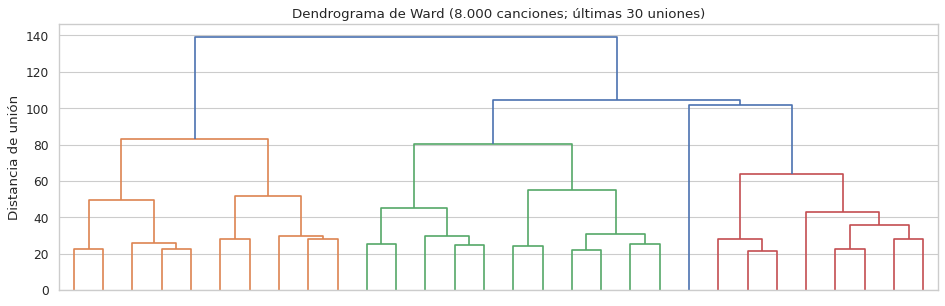

In [29]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics import adjusted_rand_score

# Ward necesita memoria cuadrática en la cantidad de canciones: se usa una muestra de 8.000 (semilla 42).
muestra_ward = np.random.default_rng(SEMILLA).choice(len(Z), 8000, replace=False)
Z_ward = Z[muestra_ward]
enlace = linkage(Z_ward, method="ward")

filas_ward = []
for k in range(2, 7):
    etiquetas = fcluster(enlace, k, criterion="maxclust")
    filas_ward.append({"K": k, "Silueta": silhouette_score(Z_ward, etiquetas),
                       "Davies-Bouldin": davies_bouldin_score(Z_ward, etiquetas)})
print("Ward con distintos K:")
display(pd.DataFrame(filas_ward).round(3))

grupos_ward = fcluster(enlace, K_ELEGIDO, criterion="maxclust")
grupos_km = kmeans.labels_[muestra_ward]
print("Misma muestra y K = 4:")
display(pd.DataFrame([
    {"Algoritmo": "K-Means", "Silueta": silhouette_score(Z_ward, grupos_km),
     "Davies-Bouldin": davies_bouldin_score(Z_ward, grupos_km)},
    {"Algoritmo": "Jerárquico (Ward)", "Silueta": silhouette_score(Z_ward, grupos_ward),
     "Davies-Bouldin": davies_bouldin_score(Z_ward, grupos_ward)},
]).round(3))

cruce = pd.crosstab(pd.Series(grupos_km, name="Grupo K-Means"), pd.Series(grupos_ward, name="Grupo Ward"))
print("Canciones según el grupo asignado por cada algoritmo:")
display(cruce)
print(f"Índice de Rand ajustado: {adjusted_rand_score(grupos_km, grupos_ward):.3f}")
print(f"Canciones en el grupo Ward más frecuente de su grupo K-Means: "
      f"{cruce.max(axis=1).sum() / cruce.values.sum() * 100:.1f} %")

popularidad_muestra = pd.Series(datos["popularity"].values[muestra_ward])
perfil_ward = pd.DataFrame(Z_ward, columns=variables_cluster).groupby(grupos_ward).mean()
perfil_ward.insert(0, "canciones", popularidad_muestra.groupby(grupos_ward).size().values)
perfil_ward["popularidad_media"] = popularidad_muestra.groupby(grupos_ward).mean().values
perfil_ward["pct_alto_potencial"] = (popularidad_muestra >= 50).groupby(grupos_ward).mean().values * 100
perfil_ward.index.name = "Grupo Ward"
print("Perfil de los grupos de Ward (variables en desviaciones estándar):")
display(perfil_ward.round(2))

generos_muestra = datos["track_genre"].values[muestra_ward]
for g in sorted(set(grupos_ward)):
    top = pd.Series(generos_muestra[grupos_ward == g]).value_counts(normalize=True).head(4) * 100
    print(f"Grupo Ward {g}:", ", ".join(f"{n} ({p:.0f} %)" for n, p in top.items()))

plt.figure(figsize=(12, 4))
dendrogram(enlace, truncate_mode="lastp", p=30, no_labels=True,
           color_threshold=enlace[-(K_ELEGIDO - 1), 2])
plt.title("Dendrograma de Ward (8.000 canciones; últimas 30 uniones)")
plt.ylabel("Distancia de unión")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_IMAGENES, "ep2_dendrograma_ward.png"), bbox_inches="tight")
plt.show()

**Resultados (misma muestra de 8.000 canciones y K = 4):**

| Algoritmo | Silueta | Davies-Bouldin |
|---|---:|---:|
| **K-Means** | **0,208** | **1,460** |
| Jerárquico (Ward) | 0,163 | 1,544 |

| Grupo K-Means | Grupo Ward equivalente | Coincidencia |
|---|---|---|
| 0 Intenso / eléctrico | 2 (grindcore, black-metal, drum-and-bass) | 2.212 de 2.646 (84 %) |
| 1 Acústico / tranquilo | 1 (tango, honky-tonk, disney) | 1.652 de 1.798 (92 %) |
| 3 Bailable / alegre | 4 (forro, j-idol, sertanejo) | 2.355 de 3.206 (73 %) |
| 2 Hablado | 3 (comedy 94 %) solo en parte; 234 de 350 van al grupo bailable | 102 de 350 (29 %) |

- **Tres de los cuatro perfiles son robustos:** los dos algoritmos encuentran los perfiles intenso, acústico y bailable. En total, el **80,7 %** de las canciones cae en el grupo equivalente (índice de Rand ajustado 0,50, un acuerdo moderado, esperable con grupos de bordes difusos).
- **El perfil hablado es el menos estable.** Ward aísla solo un núcleo de 102 canciones de **comedia** (94 %), con `speechiness` 7 desviaciones sobre el promedio, popularidad media 23,2 y apenas 1 % de alto potencial. El resto del perfil hablado de K-Means (rap, dancehall o funk con mucha letra) Ward lo une al grupo bailable. Es decir, el perfil hablado mezcla dos cosas: comedia hablada y música cantada con mucha letra.
- **K-Means separa mejor:** tiene mayor silueta y menor Davies-Bouldin en la misma muestra, y además puede aplicarse a las 80.235 canciones y asignar canciones nuevas a un grupo. Por eso **mantenemos K-Means** como algoritmo de perfiles y usamos Ward como validación.

**Uso para el negocio:** los perfiles intenso, acústico y bailable se pueden usar con confianza para organizar el catálogo. El perfil hablado debe revisarse manualmente, separando el contenido de comedia (que casi nunca es de alto potencial) de la música con mucha letra.

# 10. Selección del modelo final y recomendaciones

## 10.1 Resumen de resultados

In [30]:
resumen = comparacion[["Modelo", "MAE", "RMSE", "R2 ajustado", "Precisión top 10 %"]].copy()
resumen["MAE CV (5 part.)"] = resumen["Modelo"].map({
    "Ridge": cv_por_config[("Ridge", "Audio + género (15 variables)")].mean(),
    "Gradient Boosting": cv_por_config[("Gradient Boosting", "Audio + género (15 variables)")].mean()})
display(resumen.round(3))

joblib.dump(modelo_final, os.path.join(RUTA_MODELOS, "modelo_final.joblib"))
joblib.dump({"escalador": escalador_cluster, "kmeans": kmeans, "variables": variables_cluster},
            os.path.join(RUTA_MODELOS, "kmeans_perfiles.joblib"))
print(f"Modelo final ({mejor_nombre}) guardado en models/modelo_final.joblib")
print("K-Means guardado en models/kmeans_perfiles.joblib")

,Modelo,MAE,RMSE,R2 ajustado,Precisión top 10 %,MAE CV (5 part.)
0,Referencia: promedio general,15.192,18.181,-0.000,0.256,NaN
1,Referencia: promedio del género,9.881,13.669,0.431,0.756,NaN
2,Ridge,9.804,13.578,0.437,0.754,9.718
3,Random Forest,9.124,12.996,0.484,0.810,NaN
4,Gradient Boosting,9.060,12.970,0.486,0.805,8.957


Modelo final (Gradient Boosting) guardado en models/modelo_final.joblib
K-Means guardado en models/kmeans_perfiles.joblib


In [31]:
# Ejemplo de uso: predecir una canción nueva con el modelo guardado
modelo_cargado = joblib.load(os.path.join(RUTA_MODELOS, "modelo_final.joblib"))
cancion_nueva = X_test.iloc[[0]].copy()
print("Canción de ejemplo:", datos.loc[cancion_nueva.index[0], ["track_name", "artists", "track_genre"]].to_dict())
print("Popularidad real:", y_test.iloc[0], "| predicha:", round(modelo_cargado.predict(cancion_nueva)[0], 1))

Canción de ejemplo: {'track_name': 'INDUSTRY BABY (feat. Jack Harlow)', 'artists': 'Lil Nas X;Jack Harlow', 'track_genre': 'hip-hop'}
Popularidad real: 81 | predicha: 35.8


## 10.2 Modelo elegido con validación: Gradient Boosting

| Criterio | Gradient Boosting | Random Forest | Ridge |
|---|---|---|---|
| MAE en la misma validación (sección 6.2.1) | **8,88** | 9,18 | 9,65 |
| MAE en prueba (< 9,88) | **9,06** ✔ | 9,12 ✔ | 9,80 ✔ (apenas) |
| Precisión top 10 % en prueba (> 75,6 %) | 80,5 % ✔ | **81,0 %** ✔ | 75,4 % ✘ |
| R² ajustado (> 0,431) | 0,486 ✔ | 0,484 ✔ | 0,437 ✔ |
| Estabilidad (5 validaciones internas) | 8,95 ± 0,05 | No evaluado (costo) | 9,68 ± 0,03 |
| Tiempo de entrenamiento en esta ejecución | 2,5 s | 319 s | 1,0 s |

**Elegimos Gradient Boosting** porque:

1. Tuvo el **menor MAE de validación** con la misma partición que los otros dos modelos (0,3 puntos menos que Random Forest), y la prueba final lo confirmó con el menor MAE y RMSE.
2. Random Forest logra una precisión levemente mayor (81,0 % frente a 80,5 %, menos de 10 canciones de diferencia entre 1.604), pero entrenarlo toma **más de 100 veces más tiempo** en esta ejecución y el archivo del modelo pesa mucho más. Para un sello que tendría que reentrenar el modelo cuando cambien las tendencias, la rapidez de Gradient Boosting es una ventaja real.
3. Ridge no justifica su uso: es muy interpretable, pero prácticamente no supera a la regla por género y no cumple la meta de precisión.

El modelo final (con su preprocesamiento incluido en el `Pipeline`) queda guardado en `models/modelo_final.joblib`. Una canción nueva se predice directamente con sus 15 variables originales, incluyendo `duration_log` = log(duración en minutos), sin volver a escalar ni codificar manualmente.

## 10.3 Recomendaciones para el negocio

1. **Usar el modelo como apoyo a la priorización, no para estimar cifras exactas.** Ordenar las canciones candidatas por popularidad predicha y revisar el 10 % superior: 8 de cada 10 serán de alto potencial, frente a 2,6 de cada 10 al azar.
2. **Revisar con criterio humano los géneros masivos** (rock, dance, latin, reggaeton, alternative), donde el error es mucho mayor, y no descartar canciones solo por una predicción baja: el modelo subestima los grandes éxitos.
3. **No usarlo con canciones recién lanzadas sin historial**: el modelo se entrenó sin las canciones con popularidad 0.
4. **Usar los perfiles de K-Means** para organizar el catálogo y las campañas por sonido. Los perfiles intenso, acústico y bailable son robustos (los encuentran dos algoritmos distintos); el hablado conviene revisarlo manualmente, porque mezcla comedia con géneros cantados con mucha letra.
5. **Para mejorar el modelo**, el siguiente paso no es un algoritmo más complejo, sino **nuevas variables**: seguidores del artista, inversión en promoción, presencia en playlists y fecha de lanzamiento. Con las variables actuales, los dos modelos de árboles llegan a errores muy parecidos (9,06 y 9,12).

## 10.4 Conclusiones

- Los tres modelos supervisados mejoran el MAE de la regla por género, pero solo los de árboles lo hacen de forma relevante: el audio aporta información, pero de forma **no lineal** y en **interacción con el género**. Gradient Boosting cumple las metas de MAE (9,06 < 9,88), precisión (80,5 % > 75,6 %) y R² ajustado (0,486 > 0,431).
- Las pruebas con distintos conjuntos de datos mostraron que el **género** es la variable principal (4,08 puntos de MAE), que el **audio** suma 0,82 puntos solo en modelos no lineales, que **excluir la popularidad 0** mejoró 0,95 puntos en la validación de canciones positivas y que **quitar `energy`** o **agregar cuadrados** no cambia el resultado de forma relevante.
- El resultado es estable entre particiones internas (8,95 ± 0,05), pero el modelo **subestima los grandes éxitos** y es menos confiable en los géneros masivos, porque la popularidad depende de factores que el dataset no contiene.
- K-Means encontró **4 perfiles de sonido** para describir el catálogo (intenso, acústico, hablado y bailable). La separación entre ellos es moderada (silueta 0,21) y no mejoran la predicción, pero confirman que muchas etiquetas de género no corresponden a un sonido definido. **PCA** mostró que cada perfil corresponde a un extremo de uno de los tres primeros ejes del sonido, y el **agrupamiento jerárquico (Ward)** encontró los mismos perfiles intenso, acústico y bailable (80,7 % de coincidencia); el perfil hablado es el menos estable, y su núcleo es la comedia.

**Alcance:** la evaluación se realizó con canciones del mismo dataset y popularidad positiva. No garantiza desempeño en lanzamientos nuevos, artistas distintos o períodos posteriores. El modelo no debe decidir promociones de forma automática. El conjunto de prueba se usó al final para medir desempeño y explicar errores, no para retocar hiperparámetros.